# PROCESADO DE DATOS

## A. LIBRERÍAS

In [1]:
# Matplotlib: permitir hacer zoom y desplazamiento en las gráficas. Alternativa por defecto: %matplotlib inline
%matplotlib widget

# Librerías básicas procesado de datos
import pandas as pd
import os
import glob
import numpy as np
import re

# Librerías para visualización
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

## B. CARGA Y PREPROCESADO DE DATOS

Contaremos con tres fases de procesado de datos:

- Raw: datos crudos sin ninguna alteración según los descargamos de las fuentes correspondientes
- Staging: datos preprocesados para mantener una misma estructura y formato, pasados por un proceso estándar de limpieza y preprocesado pero aún sin unirlos a datos de otras fuentes distintas.
- Trusted: datos procesados y listos para el consumo, agrupando todas las fuentes y archivos de cada participante en un único elemento.

### 1. Cargar datos raw - glucosa

Los datos de glucosa de cada participante fueron tomados mediante sensores cuya medición se realiza cada cinco minutos. 

Vamos primero a cargar los archivos raw y procesar para cada usuario un archivo de glucosa cada cinco minutos. Posteriormente crearemos un archivo extendido a raíz de éste con datos cada minuto (aunque el código permitirá adaptar este intervalo de tiempo) por si fuera necesario tener mayor granularidad en un futuro.

Generaremos archivos con resúmenes diagnósticos antes y después de cada procesado, para poder hacer un seguimiento y control de calidad de los procesos realizados, incluyendo algunas métricas importantes como el número de ceros y NaNs en cada fase.

#### 1.1 Glucosa cada 5 minutos

Dependiendo del tipo de sistema operativo y la versión del mismo que usara cada participante encontramos diferencias en los datos en crudo, por lo que necesitamos establecer tres tipos diferentes de archivos csv para adaptar el proceso de carga a cada uno de ellos. 
También realizamos una separación en subseries para que participantes que tengan muestras de datos en períodos temporales muy separados se consideren como subseries independientes.

Llevamos a cabo un proceso de normalización de variables estándar, e incluimos algunas variables como el "user_id" de cada particpante o en "os" el sistema operativo que utilizó. 

Para darle sentido fisiológico a los datos, convertimos los datos con valor cero en variables como la glucosa o el ritmo cardiaco a NaNs, e imputamos pequeños gaps sin datos mediante interpolación lineal. Para los datos faltantes del resto de variables que no presenten un conflicto con su significado fisiológico imputamos valores de cero en los datos faltantes.

In [2]:
##############################################################
#                 CONFIGURACIÓN DE RUTAS                     #
##############################################################

RAW_DIR = "Data/Raw/Glucosa"
STAGING_DIR = "Data/Staging/Glucosa"
RESUMEN_RAW = "Data/resumen_diagnostico_glucosa_raw.csv"
RESUMEN_STAGING = "Data/resumen_diagnostico_glucosa_staging.csv"

##############################################################
#                CARGA DE ARCHIVOS SEGÚN TIPO                #
##############################################################

def cargar_csv(file_path):
    """
    Carga un archivo CSV según su tipo, detectando el separador por el nombre.

    Args:
        file_path (str): Ruta completa al archivo CSV.

    Returns:
        pd.DataFrame: DataFrame con los datos cargados, índice temporal.

    Ejemplo:
        >>> df = cargar_csv("Data/Raw/Glucosa/CIS-UCM0001P.csv")

    Recomendaciones:
        - El archivo debe tener columna 'time'.
        - Si el tipo de archivo no está en las listas, lanzará un error.
    """
    nombre = os.path.splitext(os.path.basename(file_path))[0]
    tipo_1 = ["CIS-UCM0001P", "CIS-UCM0004P"]
    tipo_2 = ["CIS-UCM0005P", "CIS-UCM0006P", "CIS-UCM0007P"]
    tipo_3 = ["U10", "U12", "U13"]
    if nombre in tipo_1:
        sep = ';'
    elif nombre in tipo_2 or nombre in tipo_3:
        sep = ','
    else:
        raise ValueError(f"Archivo {nombre} no clasificado en tipo 1, 2 o 3")
    try:
        data = pd.read_csv(file_path, sep=sep, parse_dates=["time"], index_col="time")
    except ValueError:
        data = pd.read_csv(file_path, sep=sep)
        data["time"] = pd.to_datetime(data["time"], errors='coerce')
        data.set_index("time", inplace=True)
    return data

##############################################################
#                 NORMALIZACIÓN Y FORMATEO                   #
##############################################################

column_map = {'glucemias': 'glucose'}

def unificar_columnas(df):
    """
    Normaliza nombres de columnas: minúsculas, sin espacios, renombra según 'column_map'.

    Args:
        df (pd.DataFrame): DataFrame de entrada.

    Returns:
        pd.DataFrame: DataFrame con columnas unificadas.

    Ejemplo:
        >>> df = pd.DataFrame({' Glucemias ': [100, 110], 'Time': ['2024-01-01 00:00:00', '2024-01-01 01:00:00']})
        >>> df = unificar_columnas(df)
        >>> print(df.columns)
        Index(['glucose', 'time'], dtype='object')

    Recomendaciones:
        - Llamar siempre tras la carga para evitar errores por nombres inconsistentes.
    """
    df.columns = [col.strip().lower() for col in df.columns]
    df.rename(columns=column_map, inplace=True)
    return df

def normalizar_formato_time(df):
    """
    Asegura que el índice temporal sea tipo DatetimeIndex y lo normaliza a milisegundos.

    Args:
        df (pd.DataFrame): DataFrame con o sin columna 'time'.

    Returns:
        pd.DataFrame: DataFrame con índice temporal normalizado.

    Ejemplo:
        >>> df = pd.DataFrame({'time': ['2024-01-01 00:00:00.12345', '2024-01-01 01:00:00.6789'], 'glucose': [100, 110]})
        >>> df = normalizar_formato_time(df)
        >>> print(df.index)
        DatetimeIndex(['2024-01-01 00:00:00.123000', '2024-01-01 01:00:00.679000'], dtype='datetime64[ns]', name='time', freq=None)

    Recomendaciones:
        - Verifica que la columna 'time' existe antes de llamar a esta función.
    """
    if 'time' in df.columns:
        df['time'] = pd.to_datetime(df['time'], errors='coerce')
        df.set_index('time', inplace=True)
    if not isinstance(df.index, pd.DatetimeIndex):
        raise TypeError("El índice del DataFrame no es un DatetimeIndex.")
    df.index = pd.to_datetime(df.index)
    df.index = df.index.round('1ms')
    return df

##############################################################
#                     AÑADIR VARIABLES                       #
##############################################################

def extraer_user_id_de_nombre(file_path):
    """
    Extrae el identificador de usuario a partir del nombre del archivo.

    Args:
        file_path (str): Ruta del archivo original.

    Returns:
        str: user_id extraído.

    Ejemplo:
        >>> extraer_user_id_de_nombre("Data/Raw/Glucosa/U10.csv")
        'U10'
    """
    base_name = os.path.basename(file_path)
    base_name_no_ext = os.path.splitext(base_name)[0]
    return base_name_no_ext

def añadir_user_id(df, file_path):
    """
    Añade una columna 'user_id' al DataFrame según el nombre del archivo.

    Args:
        df (pd.DataFrame): DataFrame de entrada.
        file_path (str): Ruta del archivo original.

    Returns:
        pd.DataFrame: DataFrame con columna 'user_id' añadida.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [100, 110]})
        >>> df = añadir_user_id(df, "U10.csv")
        >>> print(df['user_id'].unique())
        ['U10']
    """
    user_id = extraer_user_id_de_nombre(file_path)
    df["user_id"] = user_id
    return df

def añadir_os(df, file_path):
    """
    Añade columna 'os': 1 si el archivo comienza por 'U', 0 si comienza por 'CIS'.

    Args:
        df (pd.DataFrame): DataFrame de entrada.
        file_path (str): Ruta del archivo original.

    Returns:
        pd.DataFrame: DataFrame con columna 'os' añadida.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [100, 110]})
        >>> df = añadir_os(df, "U10.csv")
        >>> print(df['os'].iloc[0])
        1
    """
    nombre = os.path.splitext(os.path.basename(file_path))[0]
    df['os'] = 1 if nombre.startswith("U") else 0
    return df

##############################################################
#            CEROS A NAN EN VARIABLES FISIOLÓGICAS           #
##############################################################

def ceros_a_nan(df, columnas):
    """
    Convierte los valores 0 en las columnas indicadas a NaN.

    Args:
        df (pd.DataFrame): DataFrame de entrada.
        columnas (list): Lista de columnas a limpiar.

    Returns:
        pd.DataFrame: DataFrame con ceros convertidos a NaN en las columnas indicadas.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [0, 100, 0, 120], 'heart_rate': [0, 70, 80, 0]})
        >>> df = ceros_a_nan(df, ['glucose', 'heart_rate'])
        >>> print(df)
           glucose  heart_rate
        0      NaN         NaN
        1    100.0        70.0
        2      NaN        80.0
        3    120.0         NaN

    Recomendaciones:
        - Útil para limpiar ceros imposibles en variables fisiológicas.
    """
    for col in columnas:
        if col in df.columns:
            df[col] = df[col].replace([0], [np.nan])
    return df

##############################################################
#                   INTERPOLACIÓN (LINEAL)                   #
##############################################################

def interpolar_lineal_limited(df, col, max_gap=3):
    """
    Imputa huecos consecutivos (hasta max_gap) con interpolación lineal.

    Args:
        df (pd.DataFrame): DataFrame de entrada.
        col (str): Nombre de la columna a imputar.
        max_gap (int): Tamaño máximo de gap a rellenar.

    Returns:
        pd.Series: Serie con huecos pequeños interpolados.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [100, None, None, 130, 140]})
        >>> df['glucose'] = interpolar_lineal_limited(df, 'glucose', max_gap=2)
        >>> print(df['glucose'].tolist())
        [100.0, 110.0, 120.0, 130.0, 140.0]
    """
    return df[col].interpolate(method='linear', limit=max_gap, limit_direction='both')

def imputar_valores_faltantes(df):
    """
    Imputa valores faltantes:
    - 'glucose' y 'heart_rate': interpolación lineal para huecos pequeños.
    - 'steps' y 'calories': se imputan con cero.

    Args:
        df (pd.DataFrame): DataFrame de entrada.

    Returns:
        pd.DataFrame: DataFrame con valores imputados.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [100, None, None, 130], 'steps': [None, 2, 3, None]})
        >>> df = imputar_valores_faltantes(df)
        >>> print(df)
           glucose  steps
        0    100.0    0.0
        1    110.0    2.0
        2    120.0    3.0
        3    130.0    0.0
    """
    for col in ['glucose', 'heart_rate']:
        if col in df.columns:
            df[col] = interpolar_lineal_limited(df, col, max_gap=3)
    for col in ['steps', 'calories']:
        if col in df.columns:
            df[col] = df[col].fillna(0)
    return df

##############################################################
#                 SEPARACIÓN EN SUBSERIES                    #
##############################################################

def dividir_por_faltantes(df, columna, max_gap, min_valid_period):
    """
    Divide una serie temporal en subseries, cortando donde hay gaps mayores a max_gap.

    Args:
        df (pd.DataFrame): DataFrame de entrada.
        columna (str): Columna a analizar para gaps.
        max_gap (int): Máximo gap permitido antes de dividir.
        min_valid_period (int): Mínimo de registros válidos para aceptar una subserie.

    Returns:
        dict: Diccionario {nombre_subserie: DataFrame_subserie}.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [100, None, None, 130, None, None, None, 140, 150]})
        >>> subseries = dividir_por_faltantes(df, 'glucose', max_gap=2, min_valid_period=2)
        >>> for k, v in subseries.items():
        ...     print(k, v['glucose'].tolist())
        serie1 [100.0, nan, nan, 130.0]
        serie2 [140.0, 150.0]

    Recomendaciones:
        - Usar tras normalizar e imputar los huecos pequeños.
        - Ajustar min_valid_period para evitar subseries demasiado cortas.
    """
    subseries = {}
    gap_counts = df[columna].isna().astype(int).groupby(df[columna].notna().cumsum()).cumsum()
    serie_id = 1
    current_subserie = []
    for group, indices in df.groupby((gap_counts > max_gap).cumsum()):
        valid_period = indices[columna].notna().astype(int).rolling(window=min_valid_period).sum()
        if valid_period.max() >= min_valid_period:
            if current_subserie:
                subseries[f"serie{serie_id}"] = pd.concat(current_subserie)
                serie_id += 1
            current_subserie = [indices]
        elif current_subserie:
            current_subserie.append(indices)
    if current_subserie:
        subseries[f"serie{serie_id}"] = pd.concat(current_subserie)
    return subseries

def dividir_por_usuario_y_faltantes(df, user_col, data_col, max_gap, min_valid_period):
    """
    Divide el DataFrame en subseries por usuario y por gaps en una columna.

    Args:
        df (pd.DataFrame): DataFrame original.
        user_col (str): Columna de usuario.
        data_col (str): Columna a analizar para gaps.
        max_gap (int): Máximo gap permitido antes de dividir.
        min_valid_period (int): Mínimo registros válidos para nueva subserie.

    Returns:
        dict: Diccionario {nombre_subserie: DataFrame_subserie}.

    Ejemplo:
        >>> df = pd.DataFrame({'user_id': ['A', 'A', 'A', 'B', 'B'], 'glucose': [1, None, 3, 4, None]})
        >>> subseries = dividir_por_usuario_y_faltantes(df, 'user_id', 'glucose', 1, 1)
        >>> print(list(subseries.keys()))
        ['A_serie1', 'B_serie1']

    Recomendaciones:
        - Útil para analizar la continuidad de datos por usuario.
    """
    all_subseries = {}
    users = df[user_col].unique()
    for user_id in users:
        user_data = df[df[user_col] == user_id]
        subseries = dividir_por_faltantes(user_data, data_col, max_gap, min_valid_period)
        for sub_name, sub_df in subseries.items():
            new_name = f"{user_id}_{sub_name}"
            all_subseries[new_name] = sub_df
    return all_subseries

def dividir_subseries(df, file_path, data_col="glucose", max_gap=12, min_valid=24):
    """
    Divide el DataFrame en subseries. Si solo hay una subserie, usa el nombre base.

    Args:
        df (pd.DataFrame): DataFrame procesado.
        file_path (str): Ruta del archivo original.
        data_col (str): Columna para detectar huecos.
        max_gap (int): Gap máximo para dividir.
        min_valid (int): Mínimo registros válidos para subserie.

    Returns:
        dict: Diccionario {nombre_subserie: DataFrame_subserie}.

    Ejemplo:
        >>> df = pd.DataFrame({'user_id': ['A']*5, 'glucose': [1, None, None, 4, 5]})
        >>> subseries = dividir_subseries(df, "A.csv", data_col="glucose", max_gap=1, min_valid=2)
        >>> print(list(subseries.keys()))
        ['A']  # si solo hay una subserie

    Recomendaciones:
        - Así, si solo hay una subserie, el archivo guardado será el nombre base.
    """
    user_id = df["user_id"].iloc[0]
    subseries = dividir_por_usuario_y_faltantes(df, "user_id", data_col, max_gap, min_valid)
    if len(subseries) == 1:
        return {user_id: list(subseries.values())[0]}
    elif len(subseries) > 1:
        return subseries
    else:
        return {user_id: df}

##############################################################
#                 RESÚMENES DIAGNÓSTICOS                     #
##############################################################

def generar_resumen_diagnostico(df, file_path):
    """
    Genera un resumen diagnóstico del DataFrame.

    Args:
        df (pd.DataFrame): DataFrame a resumir.
        file_path (str): Ruta o nombre de archivo (para identificar).

    Returns:
        dict: Resumen con métricas de calidad de datos.

    Ejemplo:
        >>> df = pd.DataFrame({'glucose': [100, None, 0], 'os': [1, 1, 1], 'steps': [0, 2, 0]})
        >>> resumen = generar_resumen_diagnostico(df, "U10.csv")
        >>> print(resumen)
        {'archivo': 'U10.csv', 'os': 1, 'rows': 3, 'nulos_glucose': 1, 'ceros_glucose': 1, ...}

    Recomendaciones:
        - Útil para comparar la calidad de los datos antes y después de la limpieza.
    """
    resumen = {
        'archivo': os.path.basename(file_path),
        'os': df['os'].iloc[0] if 'os' in df.columns else None,
        'rows': len(df),
        'nulos_glucose': df['glucose'].isna().sum() if 'glucose' in df.columns else None,
        'ceros_glucose': (df['glucose'] == 0).sum() if 'glucose' in df.columns else None,
        'nulos_heart_rate': df['heart_rate'].isna().sum() if 'heart_rate' in df.columns else None,
        'ceros_heart_rate': (df['heart_rate'] == 0).sum() if 'heart_rate' in df.columns else None,
        'ceros_steps': (df['steps'] == 0).sum() if 'steps' in df.columns else None,
        'ceros_calories': (df['calories'] == 0).sum() if 'calories' in df.columns else None,
    }
    return resumen

##############################################################
#              FUNCIÓN PRINCIPAL DE PROCESADO                #
##############################################################

def procesar_archivo_csv(file_path):
    """
    Procesa un archivo CSV:
      1. Carga y normaliza datos.
      2. Añade metadatos y genera resumen inicial.
      3. Divide en subseries (si aplica).
      4. Convierte ceros a NaN en variables fisiológicas en cada subserie.
      5. Imputa/interpola en cada subserie.
      6. Guarda cada subserie limpia e imputada.
      7. Genera resúmenes diagnósticos finales.

    Args:
        file_path (str): Ruta del archivo CSV original.

    Returns:
        tuple: (resumen_pre, resumenes_final)

    Ejemplo:
        >>> resumen_pre, resumenes_final = procesar_archivo_csv("Data/Raw/Glucosa/U10.csv")
        >>> print(resumen_pre)
        >>> print(resumenes_final)

    Recomendaciones:
        - Llama esta función desde el pipeline principal sobre cada archivo raw.
        - Los archivos de salida estarán ya limpios y listos para trusted/extensión.
    """

    # 1. Cargar y normalizar
    data = cargar_csv(file_path)
    data = unificar_columnas(data)
    data = normalizar_formato_time(data)
    data = añadir_user_id(data, file_path)
    data = añadir_os(data, file_path)

    # 2. Resumen diagnóstico inicial (raw, antes de imputar)
    resumen_pre = generar_resumen_diagnostico(data, file_path)

    # 3. Dividir en subseries (usando solo los NaN originales)
    gap_threshold = 12
    min_valid_duration = 24
    subseries = dividir_subseries(
        df=data,
        file_path=file_path,
        data_col="glucose",
        max_gap=gap_threshold,
        min_valid=min_valid_duration
    )
    resumenes_final = []
    
    # 4. Para cada subserie: convertir ceros a NaN, imputar/interpolar, guardar y resumir
    for nombre, sub_df in subseries.items():
        sub_df = ceros_a_nan(sub_df, ['glucose', 'heart_rate'])
        sub_df = imputar_valores_faltantes(sub_df)
        user_id = sub_df["user_id"].iloc[0]
        if nombre == user_id:
            nombre_archivo = f"{user_id}.csv"
        else:
            nombre_archivo = f"{nombre}.csv"
        ruta_salida = os.path.join(STAGING_DIR, nombre_archivo)
        sub_df.to_csv(ruta_salida, index=True, date_format="%Y-%m-%d %H:%M:%S.%f", na_rep='NaN')
        resumen = generar_resumen_diagnostico(sub_df, nombre)
        resumenes_final.append(resumen)
    return resumen_pre, resumenes_final

##############################################################
#                       PIPELINE PRINCIPAL                   #
##############################################################

def main():
    """
    Ejecuta el pipeline completo:
      - Procesa todos los archivos CSV de la carpeta RAW.
      - Genera y guarda resúmenes diagnósticos iniciales y finales.

    Returns:
        None

    Ejemplo:
        >>> main()

    Recomendaciones:
        - Los archivos procesados se guardan en la carpeta de staging.
        - El resumen de diagnóstico permite auditar la calidad de los datos.
    """
    csv_files = glob.glob(os.path.join(RAW_DIR, "*.csv"))
    resumenes_pre = []
    resumenes_post = []

    for file_path in csv_files:
        try:
            resumen_pre, resumenes_final = procesar_archivo_csv(file_path)
            resumenes_pre.append(resumen_pre)
            resumenes_post.extend(resumenes_final)
        except Exception as e:
            print(f"Error procesando {file_path}: {e}")

    pd.DataFrame(resumenes_pre).to_csv(RESUMEN_RAW, index=False)
    print(f"\nResumen de diagnóstico de datos raw guardado en: {RESUMEN_RAW}")
    pd.DataFrame(resumenes_post).to_csv(RESUMEN_STAGING, index=False)
    print(f"Resumen de diagnóstico de datos staging guardado en: {RESUMEN_STAGING}")

if __name__ == "__main__":
    main()



Resumen de diagnóstico de datos raw guardado en: Data/resumen_diagnostico_glucosa_raw.csv
Resumen de diagnóstico de datos staging guardado en: Data/resumen_diagnostico_glucosa_staging.csv


Comprobamos los resúmenes diagnósticos tanto de los datos raw como de los datos en staging para ver que los procesos anteriores se han realizado correctamente.

In [3]:
resumen_glucosa_raw = pd.read_csv(RESUMEN_RAW)
resumen_glucosa_raw

,archivo,os,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,ceros_steps,ceros_calories
0,CIS-UCM0001P.csv,0,8343,2643,0,233,0,0,0
1,CIS-UCM0004P.csv,0,14699,6422,0,123,0,0,0
2,CIS-UCM0005P.csv,0,2307,0,0,0,0,1776,1667
3,CIS-UCM0006P.csv,0,2541,0,0,0,0,2218,2110
4,CIS-UCM0007P.csv,0,501,0,0,0,0,409,327
5,U10.csv,1,3973,0,748,0,3630,3462,3971
6,U12.csv,1,3205,0,1080,0,2486,3194,3194
7,U13.csv,1,5785,0,3073,0,5311,5769,5785


In [4]:
resumen_glucosa_staging = pd.read_csv(RESUMEN_STAGING)
resumen_glucosa_staging

,archivo,os,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,ceros_steps,ceros_calories
0,CIS-UCM0001P_serie1,0,3269,421,0,105,0,2764,3144
1,CIS-UCM0001P_serie2,0,4791,1931,0,71,0,3895,4688
2,CIS-UCM0004P_serie1,0,3002,227,0,21,0,2613,2749
3,CIS-UCM0004P_serie2,0,8996,6150,0,26,0,7246,8684
4,CIS-UCM0004P_serie3,0,2701,33,0,19,0,2139,2579
5,CIS-UCM0005P,0,2307,0,0,0,0,1776,1667
6,CIS-UCM0006P,0,2541,0,0,0,0,2218,2110
7,CIS-UCM0007P,0,501,0,0,0,0,409,327
8,U10,1,3973,383,0,2993,0,3462,3971
9,U12,1,3205,909,0,931,0,3194,3194


Vemos que los archivos en staging ya no presentan ceros en variables fisiológicas importantes como la glucosa o el ritmo cardiaco. Sin embargo, algunos de estos datos han pasado ahora a ser NaNs, que es algo que en adelante tendremos que tener en cuenta al realizar diferentes procesos y análisis.

Vemos que tanto en 'steps' como en 'calories' el número de datos por participante es muy bajo, por lo que probablemente no serán datos que podamos utilizar como base en nuestros análisis posteriores.

#### 1.2 Glucosa extendida 60s

Vamos a crear un archivo equivalente para cada participante extendiendo los datos de glucosa a cada minuto (aunque el código permite establecer el intervalo de tiempo a elección del usuario), ya que puede ser interesante en un futuro tener una granularidad mayor dado que las variables fisiológicas pueden verse modificadas rápido en intervalos de tiempo corto.

Para evitar repetir los mismos datos, que puede alterar procesos posteriores, hacemos esta extensión mediante una interpolación de los datos conocidos (aunque el código admite hacer un forward-fill copiando los datos existentes).

In [5]:
def extender_datos_glucosa(df, intervalo, metodo="interpolar"):
    """
    Extiende los datos de glucosa a un intervalo regular usando el método especificado.

    Args:
        df (pd.DataFrame): DataFrame con columna 'time' (datetime) y 'glucose'.
        intervalo (int): Intervalo en segundos (ejemplo: 60 para 1 minuto).
        metodo (str): 'copiar' (forward fill) o 'interpolar' (interpolación lineal).

    Returns:
        pd.DataFrame: DataFrame extendido y rellenado, con columna 'time' como datetime.

    Ejemplo:
        >>> import pandas as pd
        >>> df = pd.DataFrame({
        ...     'time': pd.to_datetime(['2024-01-01 12:00:00', '2024-01-01 12:05:00']),
        ...     'glucose': [10, 20]
        ... })
        >>> df_ext = extender_datos_glucosa(df, intervalo=60, metodo='copiar')
        >>> print(df_ext[['time', 'glucose']].head(7))
                        time  glucose
        0 2024-01-01 12:00:00     10.0
        1 2024-01-01 12:01:00     10.0
        2 2024-01-01 12:02:00     10.0
        3 2024-01-01 12:03:00     10.0
        4 2024-01-01 12:04:00     10.0
        5 2024-01-01 12:05:00     20.0

        >>> df_ext = extender_datos_glucosa(df, intervalo=60, metodo='interpolar')
        >>> print(df_ext[['time', 'glucose']].head(7))
                        time  glucose
        0 2024-01-01 12:00:00   10.0
        1 2024-01-01 12:01:00   12.0
        2 2024-01-01 12:02:00   14.0
        3 2024-01-01 12:03:00   16.0
        4 2024-01-01 12:04:00   18.0
        5 2024-01-01 12:05:00   20.0

    Recomendaciones:
        - 'intervalo' debe ser un entero en segundos (ej: 300 para 5 minutos).
        - La columna 'time' debe estar en formato datetime64[ns] y monotónica.
        - Si el método es 'interpolar', asegúrate de que 'time' es único y ordenado.
        - Si el método es 'interpolar' y hay nulos previos serán interpolados y en el extendido desaparecen
    """
    df = df.copy()
    if 'time' not in df.columns:
        raise ValueError("El DataFrame debe tener una columna 'time'.")
    if not pd.api.types.is_datetime64_any_dtype(df['time']):
        df['time'] = pd.to_datetime(df['time'], errors='coerce')
    df = df.sort_values('time')
    df.set_index('time', inplace=True)

    nuevo_indice = pd.date_range(start=df.index.min(), end=df.index.max(), freq=f"{intervalo}s")

    if metodo == "copiar":
        df_extendido = df.reindex(nuevo_indice, method="pad")
    elif metodo == "interpolar":
        df_extendido = df.reindex(nuevo_indice)
        for col in ["glucose", "heart_rate"]:
            if col in df_extendido.columns:
                df_extendido[col] = df_extendido[col].interpolate(method="linear", limit_direction="both")
    else:
        raise ValueError("Método no reconocido. Usa 'copiar' o 'interpolar'.")

    for col in ["steps", "calories"]:
        if col in df_extendido.columns:
            df_extendido[col] = df_extendido[col].fillna(0)

    # Mantener constantes 'user_id' y 'os'
    for col in ["user_id", "os"]:
        if col in df_extendido.columns:
            valores_unicos = df[col].dropna().unique()
            if len(valores_unicos) == 1:
                df_extendido[col] = valores_unicos[0]
                # Debemos asegurarnos de que 'os' es int (pandas lo convierte a float)
                if col == "os":
                    df_extendido[col] = int(valores_unicos[0])
            else:
                raise ValueError(f"La columna '{col}' no es única en la subserie extendida.")

    df_extendido.reset_index(inplace=True)
    df_extendido.rename(columns={"index": "time"}, inplace=True)
    return df_extendido

def procesar_y_guardar_extendido_staging(file_path, intervalo, metodo, destino_dir):
    """
    Procesa un archivo de subserie de staging, extiende/interpola y guarda el resultado.

    Args:
        file_path (str): Ruta del archivo CSV de staging (subserie).
        intervalo (int): Intervalo en segundos para el nuevo índice temporal.
        metodo (str): 'copiar', 'media', o 'interpolacion'.
        destino_dir (str): Directorio donde se guardará el archivo extendido.

    Returns:
        pd.DataFrame: DataFrame extendido (ya guardado en disco).
        str: Ruta del archivo guardado.

    Ejemplo:
        >>> procesar_y_guardar_extendido_staging("U10_serie1.csv", 60, "interpolacion", "./salida")

    Recomendaciones:
        - El archivo de entrada debe tener columna 'time' y estar limpio (como en staging).
        - El archivo de salida tendrá el nombre original + intervalo + método.
    """
    df = pd.read_csv(file_path)

    df_extendido = extender_datos_glucosa(df, intervalo, metodo)
    base_name = os.path.basename(file_path)
    name, _ = os.path.splitext(base_name)
    nuevo_nombre = f"{name}_{intervalo}_{metodo}.csv"
    ruta_salida = os.path.join(destino_dir, nuevo_nombre)
    os.makedirs(destino_dir, exist_ok=True)

    df_extendido.to_csv(ruta_salida, index=False)
    return df_extendido, ruta_salida

def main():
    """
    Ejecuta el pipeline de extensión/interpolación temporal para todos los archivos de subseries en staging.

    Returns:
        None

    Ejemplo:
        >>> main()

    Recomendaciones:
        - Ajusta 'intervalos' y 'metodo' según tus necesidades de granularidad.
        - El directorio de staging debe contener los CSVs de subseries limpias.
        - El resumen final permite comparar la calidad de los datos tras la extensión.
    """
    staging_dir = "Data/Staging/Glucosa"
    destino_dir = "Data/Staging/Glucosa/Glucosa extendida"
    intervalos = [60]  # 60 segundos (1 min), 300 segundos (5 min)
    metodo = "interpolar"
    csv_files = glob.glob(os.path.join(staging_dir, "*.csv"))

    for intervalo in intervalos:
        resumenes = []
        for file_path in csv_files:
            try:
                df_extendido, ruta_salida = procesar_y_guardar_extendido_staging(
                    file_path, intervalo, metodo, destino_dir
                )
                resumenes.append(generar_resumen_diagnostico(df_extendido, ruta_salida))
                print(f"Archivo extendido guardado en: {ruta_salida}")
            except Exception as e:
                print(f"Error procesando {file_path} (intervalo {intervalo}): {e}")

        resumen_df = pd.DataFrame(resumenes)
        resumen_path = os.path.join("Data", f"resumen_diagnostico_glucosa_extendida_staging_{intervalo}_{metodo}.csv")
        resumen_df.to_csv(resumen_path, index=False)
        print(f"Resumen de diagnóstico guardado en: {resumen_path}")

if __name__ == "__main__":
    main()


Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0001P_serie1_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0001P_serie2_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0004P_serie1_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0004P_serie2_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0004P_serie3_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0005P_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0006P_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\CIS-UCM0007P_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa extendida\U10_60_interpolar.csv
Archivo extendido guardado en: Data/Staging/Glucosa/Glucosa exten

Ahora comprobamos los resúmenes diagnósticos generados para hacer un control de calidad de los datos.

In [6]:
resumen_glucosa_staging = pd.read_csv(RESUMEN_STAGING)
resumen_glucosa_staging

,archivo,os,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,ceros_steps,ceros_calories
0,CIS-UCM0001P_serie1,0,3269,421,0,105,0,2764,3144
1,CIS-UCM0001P_serie2,0,4791,1931,0,71,0,3895,4688
2,CIS-UCM0004P_serie1,0,3002,227,0,21,0,2613,2749
3,CIS-UCM0004P_serie2,0,8996,6150,0,26,0,7246,8684
4,CIS-UCM0004P_serie3,0,2701,33,0,19,0,2139,2579
5,CIS-UCM0005P,0,2307,0,0,0,0,1776,1667
6,CIS-UCM0006P,0,2541,0,0,0,0,2218,2110
7,CIS-UCM0007P,0,501,0,0,0,0,409,327
8,U10,1,3973,383,0,2993,0,3462,3971
9,U12,1,3205,909,0,931,0,3194,3194


In [7]:
resumen_glucosa_extendida_staging = pd.read_csv(r"Data/resumen_diagnostico_glucosa_extendida_staging_60_interpolar.csv")
resumen_glucosa_extendida_staging

,archivo,os,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,ceros_steps,ceros_calories
0,CIS-UCM0001P_serie1_60_interpolar.csv,0,16341,0,0,0,0,15836,16216
1,CIS-UCM0001P_serie2_60_interpolar.csv,0,24736,0,0,0,0,23840,24633
2,CIS-UCM0004P_serie1_60_interpolar.csv,0,15006,0,0,0,0,14617,14753
3,CIS-UCM0004P_serie2_60_interpolar.csv,0,46056,0,0,0,0,44306,45744
4,CIS-UCM0004P_serie3_60_interpolar.csv,0,13501,0,0,0,0,12939,13379
5,CIS-UCM0005P_60_interpolar.csv,0,11531,0,0,0,0,11000,10891
6,CIS-UCM0006P_60_interpolar.csv,0,12706,0,0,0,0,12383,12275
7,CIS-UCM0007P_60_interpolar.csv,0,2531,0,0,0,0,2439,2357
8,U10_60_interpolar.csv,1,19861,0,0,0,0,19350,19859
9,U12_60_interpolar.csv,1,16021,0,0,0,0,16010,16010


Vemos que al extender los datos existentes e interpolar desaparecen los NaNs y los ceros de las variables de glucosa y ritmo cardiaco.

#### 1.3 Gráficas raw vs staging

Vamos a ver gráficamente los datos en crudo y las dos versiones de datos en fase staging, la normal cada cinco minutos y la extendida cada minuto.

In [8]:
def graficar_glucosa_participante(user_id, 
                                  raw_path="Data/Raw/Glucosa", 
                                  staging_path="Data/Staging/Glucosa", 
                                  extendidos_path="Data/Staging/Glucosa/Glucosa extendida", 
                                  variable='glucose'):
    plt.figure(figsize=(10, 6))
    
    # 1. RAW
    raw_file = os.path.join(raw_path, f"{user_id}.csv")
    if os.path.exists(raw_file):
        df_raw = cargar_csv(raw_file)
        df_raw = unificar_columnas(df_raw)
        df_raw = normalizar_formato_time(df_raw)
        if variable in df_raw.columns and not df_raw[variable].isnull().all():
            plt.plot(df_raw.index, df_raw[variable], label="Raw", linewidth=4, color='blue', alpha=0.7)
    
    # 2. STAGING
    staging_file = os.path.join(staging_path, f"{user_id}.csv")
    if os.path.exists(staging_file):
        df_staging = pd.read_csv(staging_file, parse_dates=["time"], index_col="time")
        if variable in df_staging.columns and not df_staging[variable].isnull().all():
            plt.plot(df_staging.index, df_staging[variable], label="Staging", linewidth=3, color='orange', alpha=0.8)
    
    # 3. STAGING EXTENDIDA
    archivos_ext = glob.glob(os.path.join(extendidos_path, f"{user_id}*.csv"))
    colores = ['green', 'red', 'purple', 'brown', 'gray']
    for i, archivo_ext in enumerate(archivos_ext):
        df_ext = pd.read_csv(archivo_ext, parse_dates=["time"], index_col="time")
        if variable in df_ext.columns and not df_ext[variable].isnull().all():
            nombre = os.path.basename(archivo_ext).replace(".csv", "")
            plt.plot(df_ext.index, df_ext[variable], label=f"Extendida: {nombre}", 
                     linewidth=2, linestyle="--", color=colores[i % len(colores)], alpha=0.7)
    
    plt.title(f"{user_id} - {variable}")
    plt.xlabel("Tiempo")
    plt.ylabel(variable)
    plt.legend()
    plt.tight_layout()
    plt.show()


Graficamos el caso concreto de uno de los participantes que antes tenía un elevado número de ceros y/o NaNs, y vemos las diferencias entre las tres versiones de los datos.

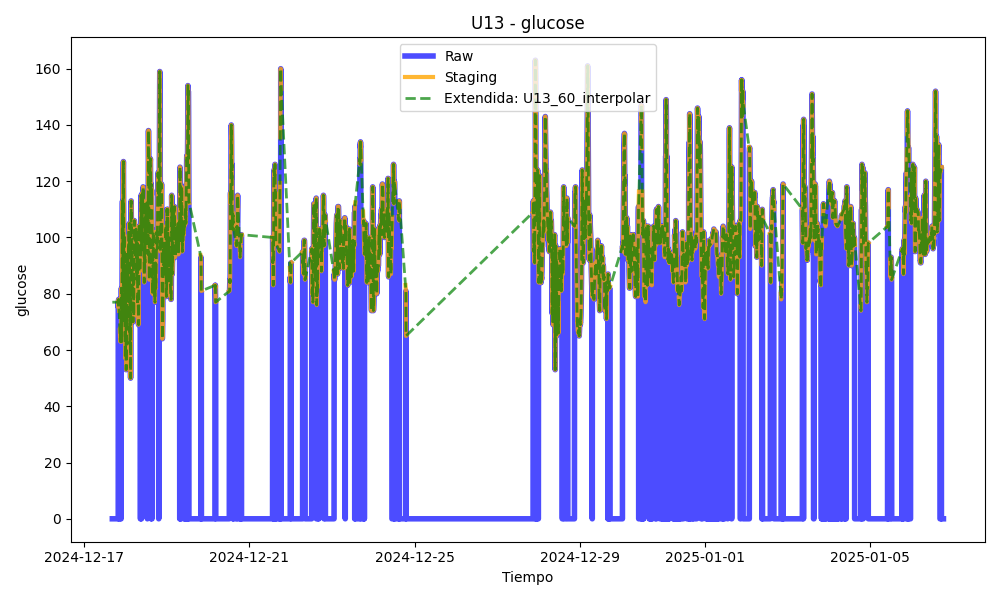

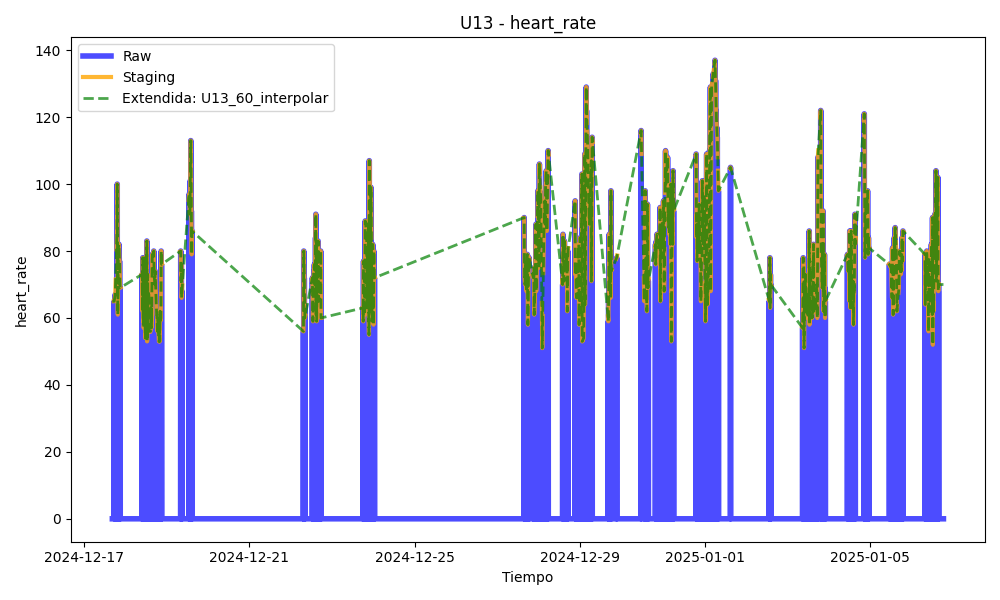

In [9]:
user_id = "U13"

variables = ['glucose', 'heart_rate']
for variable in variables:
    g = graficar_glucosa_participante(user_id, variable=variable)
    plt.title(f"{user_id} - {variable}")

In [10]:
plt.close('all')

### 2. Cargar datos raw - GPS

Ahora procedemos a realizar el proceso equivalente para los datos de GPS, aunque en este caso todos provienen de una misma fuente. 
Primero unificamos todos los datos de distintos archivos en un único elemento y luego realizamos una normalización estándar.

Vamos a crear una variable dummy categórica 'exercise' que será 0 cuando no haya ejercicio y 1 cuando sí. La forma de medir si hace o no ejercicio será si tiene datos provenientes de los archivos de GPS, en esos casos tomará el valor 1, y rellenaremos el resto de momentos temporales con 0.

En el caso de los datos GPS tenemos una granularidad mucho mayor que para la glucosa, ya que de media tenemos datos cada 0.2 segundos. 
Esta diferencia frente a los datos de glucosa nos lleva a explorar métodos de agregación para, además de crear un archivo por particpante con todos los datos existentes, crear una versión con datos agregados cada 60 segundos y cada 5 minutos, para equipararlos a los datos de glucosa anteriores, por si en un futuro queremos usar archivos donde las variables tengan la misma granularidad.

#### 2.1 GPS completo:

In [11]:
##############################################################
#               NORMALIZACIÓN DE COLUMNAS GPS                #
##############################################################

def unificar_columnas_gps(df):
    """
    Normaliza nombres de columnas: minúsculas, sin espacios, y renombra según diccionario GPS.

    Args:
        df (pd.DataFrame): DataFrame de entrada.

    Returns:
        pd.DataFrame: DataFrame con columnas unificadas.

    Ejemplo:
        >>> df = pd.DataFrame({' Latitude ': [1, 2], 'Excel Timestamp': [44927, 44928]})
        >>> df = unificar_columnas_gps(df)
        >>> print(df.columns)
        Index(['latitude', 'excel timestamp'], dtype='object')

    Recomendaciones:
        - Llama siempre antes de cualquier procesamiento específico.
    """
    df = df.copy()
    df.columns = [col.strip().lower() for col in df.columns]
    rename_map = {
        "speed": "speed",
        "latitude": "latitude",
        "longitude": "longitude",
        "accel x": "accX",
        "accel y": "accY",
        "accel z": "accZ",
        "heart rate": "heart_rate_gps"
    }
    df.rename(columns=rename_map, inplace=True)
    return df

##############################################################
#                 FORMATEO Y LIMPIEZA GPS                    #
##############################################################

def formatear_datos_gps(df):
    """
    Limpia y formatea un DataFrame de GPS para uso en staging.

    Args:
        df (pd.DataFrame): DataFrame leído de un archivo raw de GPS.

    Returns:
        pd.DataFrame: DataFrame formateado y listo para concatenar.

    Ejemplo:
        >>> df = pd.read_csv("user1_2023-01-01.csv")
        >>> df = formatear_datos_gps(df)
        >>> print(df.columns)
        Index([...], dtype='object')

    Recomendaciones:
        - Llama tras unificar columnas.
        - Si faltan columnas críticas, lanza un warning o error.
    """
    df = df.copy()
    df['exercise'] = 1
    if "excel timestamp" in df.columns:
        df["time"] = pd.to_datetime(df["excel timestamp"], unit="d", origin="1899-12-30")
        df.drop(columns=["excel timestamp"], inplace=True)
    else:
        raise ValueError("No se encontró la columna 'excel timestamp' en los datos.")
    return df

##############################################################
#              RESUMEN DIAGNÓSTICO PARA GPS                  #
##############################################################

def resumen_diagnostico_gps(df, user_id, resumen_path, medias_var=None):
    """
    Genera y añade un resumen diagnóstico de nulos y ceros para variables GPS.

    Args:
        df (pd.DataFrame): DataFrame de GPS procesado.
        user_id (str): Identificador del usuario.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.
        medias_var (dict, opcional): Diccionario de medias u otras métricas adicionales.

    Returns:
        dict: Resumen diagnóstico generado.

    Ejemplo:
        >>> resumen_diagnostico_gps(df, "user1", "Data/resumen_diagnostico_gps_raw.csv")

    Recomendaciones:
        - Llama tras leer (raw) y tras limpiar (staging) para comparar el efecto del procesamiento.
    """
    variables = ["heart_rate_gps", "speed", "latitude", "longitude", "accX", "accY", "accZ"]
    resumen = {"user_id": user_id, "rows": len(df)}
    for var in variables:
        if var in df.columns:
            resumen[f"nulos_{var}"] = df[var].isna().sum()
            resumen[f"ceros_{var}"] = df[var][~df[var].isna()].eq(0).sum()
        else:
            resumen[f"nulos_{var}"] = None
            resumen[f"ceros_{var}"] = None
    if medias_var is not None:
        resumen.update(medias_var)
    if os.path.exists(resumen_path):
        df_resumen = pd.read_csv(resumen_path)
        df_resumen = df_resumen[df_resumen['user_id'] != user_id]
        df_resumen = pd.concat([df_resumen, pd.DataFrame([resumen])], ignore_index=True)
    else:
        df_resumen = pd.DataFrame([resumen])
    df_resumen.to_csv(resumen_path, index=False)
    print(f"Resumen diagnóstico añadido a {resumen_path}")
    return resumen

##############################################################
#         PROCESADO RAW → STAGING POR USUARIO GPS            #
##############################################################

def procesar_datos_gps_completos(folder_path, resumen_raw_path, resumen_staging_path):
    """
    Une y limpia todos los archivos de GPS de un usuario, guarda el resultado en staging y genera resúmenes diagnósticos.

    Args:
        folder_path (str): Ruta de la carpeta del usuario (con archivos .csv raw).
        resumen_raw_path (str): Ruta del resumen diagnóstico raw.
        resumen_staging_path (str): Ruta del resumen diagnóstico staging.

    Returns:
        None

    Ejemplo:
        >>> procesar_datos_gps_completos("Data/Raw/GPS/user1", "Data/resumen_diagnostico_gps_raw.csv", "Data/resumen_diagnostico_gps_staging.csv")

    Recomendaciones:
        - El DataFrame final se guarda solo una vez por usuario.
        - El resumen diagnóstico se genera antes y después del procesamiento.
    """
    csv_files = glob.glob(os.path.join(folder_path, "*.csv"))
    if not csv_files:
        print(f"No se encontraron archivos en {folder_path}")
        return
    df_total = pd.DataFrame()
    for file in csv_files:
        df = pd.read_csv(file)
        df = unificar_columnas_gps(df)
        df_total = pd.concat([df_total, df], ignore_index=True)

    # Eliminar ceros de variables fisiológicas importantes:
    df_total = ceros_a_nan(df_total, ['heart_rate_gps'])

    # Resumen diagnóstico RAW sobre el conjunto unido
    resumen_diagnostico_gps(df_total, os.path.basename(folder_path), resumen_raw_path)

    # Formateo y limpieza
    df_total = formatear_datos_gps(df_total)
    if 'time' not in df_total.columns:
        raise ValueError("La columna 'time' no está presente en el DataFrame total.")
    df_total = df_total.sort_values('time').drop_duplicates(subset='time')
    df_total.set_index('time', inplace=True)
    os.makedirs("Data/Staging/GPS/Completos", exist_ok=True)
    nombre_archivo = f"{os.path.basename(folder_path)}_completo.csv"
    ruta_salida = f"Data/Staging/GPS/Completos/{nombre_archivo}"
    df_total.to_csv(ruta_salida, index=True)
    print(f"Datos completos guardados en {ruta_salida}")

    # Resumen diagnóstico STAGING sobre el conjunto limpio
    resumen_diagnostico_gps(df_total, os.path.basename(folder_path), resumen_staging_path)

##############################################################
#                       PIPELINE PRINCIPAL                   #
##############################################################

def main():
    """
    Ejecuta el pipeline raw → staging para todos los usuarios de GPS, con resúmenes diagnósticos.

    Returns:
        None

    Ejemplo:
        >>> main()

    Recomendaciones:
        - Revisa los resúmenes diagnósticos para comparar la calidad de los datos antes y después del procesamiento.
    """
    base_path = "Data/Raw/GPS"
    resumen_raw_path = "Data/resumen_diagnostico_gps_raw.csv"
    resumen_staging_path = "Data/resumen_diagnostico_gps_completo_staging.csv"
    users = [f.path for f in os.scandir(base_path) if f.is_dir()]
    for user_folder in users:
        print(f"\nProcesando usuario: {os.path.basename(user_folder)}")
        try:
            procesar_datos_gps_completos(user_folder, resumen_raw_path, resumen_staging_path)
        except Exception as e:
            print(f"Error procesando {user_folder}: {e}")

if __name__ == "__main__":
    main()



Procesando usuario: CIS-UCM0005P
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_raw.csv
Datos completos guardados en Data/Staging/GPS/Completos/CIS-UCM0005P_completo.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_completo_staging.csv

Procesando usuario: CIS-UCM0006P
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_raw.csv
Datos completos guardados en Data/Staging/GPS/Completos/CIS-UCM0006P_completo.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_completo_staging.csv

Procesando usuario: CIS-UCM0007P
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_raw.csv
Datos completos guardados en Data/Staging/GPS/Completos/CIS-UCM0007P_completo.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_completo_staging.csv

Procesando usuario: U10
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_raw.csv
Datos completos guardados en Data/Staging/GPS/Completos/U10_completo.csv
Resumen diagnóstico añadido a Data/resumen_dia

Comprobamos los resúmenes diagnóstico tanto de los datos raw (unidos en un único archivo) como de los procesados.

In [12]:
df_resumen_gps_raw = pd.read_csv("Data/resumen_diagnostico_gps_raw.csv")
df_resumen_gps_raw

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,264201,185356,0,0,38135,0,0,0,0,0,0,0,0,0,0
1,CIS-UCM0006P,171753,5116,0,0,9407,0,0,0,0,0,0,0,0,0,0
2,CIS-UCM0007P,91590,10125,0,0,17123,0,0,0,0,0,0,0,0,0,0
3,U10,253412,78933,0,0,50272,0,0,0,0,0,0,0,0,0,0
4,U12,181590,22263,0,0,39734,0,0,0,0,0,0,0,0,0,0


In [13]:
df_resumen_gps_completo_staging = pd.read_csv("Data/resumen_diagnostico_gps_completo_staging.csv")
df_resumen_gps_completo_staging

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,264201,185356,0,0,38135,0,0,0,0,0,0,0,0,0,0
1,CIS-UCM0006P,171753,5116,0,0,9407,0,0,0,0,0,0,0,0,0,0
2,CIS-UCM0007P,91590,10125,0,0,17123,0,0,0,0,0,0,0,0,0,0
3,U10,253412,78933,0,0,50272,0,0,0,0,0,0,0,0,0,0
4,U12,181590,22263,0,0,39734,0,0,0,0,0,0,0,0,0,0


##### Gráficas GPS completo:

Vamos a graficar los datos anteriores.

In [14]:

def graficar_gps_multi_eje(df, variables_primario, variable_secundario='heart_rate_gps',
                           start=None, end=None, title=None, figsize=(10, 6), color_map=None):
    """
    Grafica variables GPS con dos ejes y: uno para heart_rate_gps y otro para el resto, usando colores diferenciados.

    Args:
        df (pd.DataFrame): DataFrame con índice temporal o columna 'time'.
        variables_primario (list): Variables a mostrar en eje y primario (izquierda).
        variable_secundario (str): Variable a mostrar en eje y secundario (derecha).
        start (str, opcional): Fecha/hora de inicio.
        end (str, opcional): Fecha/hora de fin.
        title (str, opcional): Título del gráfico.
        figsize (tuple, opcional): Tamaño de la figura.
    """
    # Paleta de colores
    color_map = {
        'speed': "#ff41f9",     
        'accX': "#0c004b",      
        'accY': "#4f6ffc",      
        'accZ': "#00d0ff",      
        'latitude': "#052b00",  
        'longitude': "#00ff59", 
    }
    color_secundario = "#960002"  

    df_plot = df.copy()
    if 'time' in df_plot.columns:
        df_plot = df_plot.set_index('time')
    if start or end:
        df_plot = df_plot.loc[start:end]
    fig, ax1 = plt.subplots(figsize=figsize)

    # Eje primario
    min_y1, max_y1 = None, None
    for i, var in enumerate(variables_primario):
        if var in df_plot.columns:
            color = color_map.get(var, f'C{i}')
            ax1.plot(df_plot.index, df_plot[var], label=var, color=color)
            this_min, this_max = df_plot[var].min(), df_plot[var].max()
            min_y1 = this_min if min_y1 is None else min(min_y1, this_min)
            max_y1 = this_max if max_y1 is None else max(max_y1, this_max)
        else:
            print(f"Variable '{var}' no encontrada en el DataFrame.")

    ax1.set_xlabel("Tiempo")
    ax1.set_ylabel("Variables primarias")
    lines, labels = ax1.get_legend_handles_labels()

    # Eje secundario para heart_rate_gps
    ax2 = ax1.twinx()
    min_y2, max_y2 = None, None
    if variable_secundario in df_plot.columns:
        line_hr, = ax2.plot(df_plot.index, df_plot[variable_secundario], label=variable_secundario,
                            color=color_secundario, alpha=0.7)
        ax2.set_ylabel(variable_secundario, color=color_secundario)
        lines += [line_hr]
        labels += [variable_secundario]
        min_y2 = df_plot[variable_secundario].min()
        max_y2 = df_plot[variable_secundario].max()
    else:
        print(f"Variable '{variable_secundario}' no encontrada en el DataFrame.")

    # Alinear el cero de ambos ejes
    if min_y1 is not None and max_y1 is not None and min_y2 is not None and max_y2 is not None:
        # Calcula la posición relativa del cero en el eje primario
        if min_y1 < 0 < max_y1:
            rel0_1 = abs(min_y1) / (max_y1 - min_y1)
            # Nuevo min del secundario para que el cero esté alineado
            new_min_y2 = max_y2 - (max_y2 - min_y2) / (1 - rel0_1)
            ax2.set_ylim(bottom=new_min_y2, top=max_y2)
        else:
            # Si el eje primario no tiene valores negativos, solo iguala el bottom a cero
            ax2.set_ylim(bottom=0)

    if title:
        plt.title(title)
    else:
        plt.title(" | ".join(variables_primario) + " + " + variable_secundario)
    fig.tight_layout()
    ax1.legend(lines, labels, loc='upper left')
    plt.show()


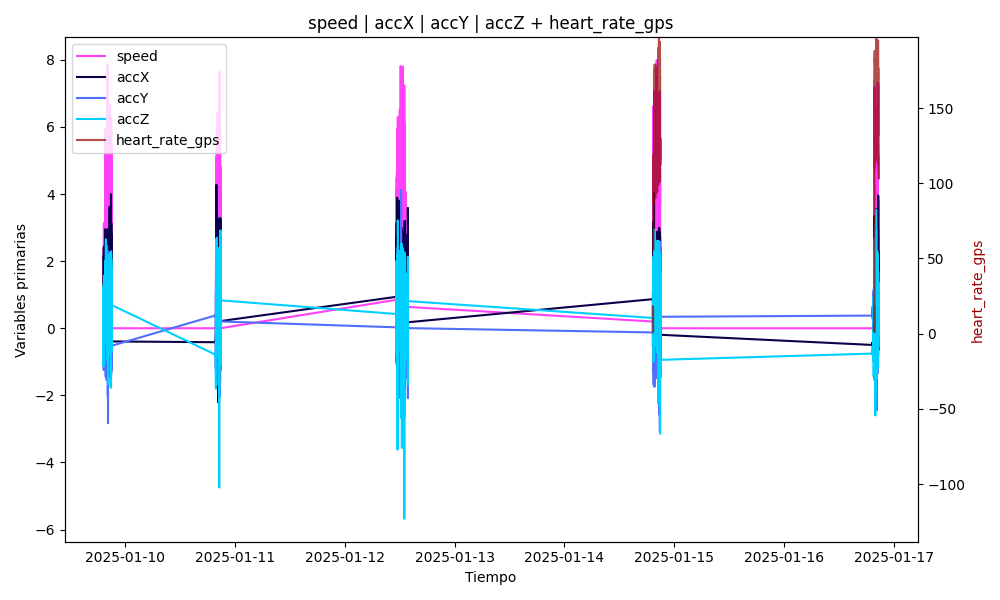

In [15]:
df = pd.read_csv(r"Data\Staging\GPS\Completos\CIS-UCM0005P_completo.csv", parse_dates=["time"], index_col="time")

# Graficar para un rango temporal concreto
#graficar_gps_multi_eje(df, ['speed'], variable_secundario='heart_rate_gps', start='2023-01-01', end='2023-01-03')

graficar_gps_multi_eje(df, ['speed', 'accX', 'accY', 'accZ'], variable_secundario='heart_rate_gps')

In [16]:
plt.close('all')

#### 2.2 GPS agrupado:

Creamos, a raíz del resultado del proceso anterior, un archivo por participante que agrupe los datos de un intervalo temporal en un único dato. 

Aunque el código permite seleccionar dichos intervalos, hemos escogido 60 segundos y 5 minutos por defecto para equipararlos a los datos anteriores de glucosa. También permite seleccionar cómo definir el dato a mostrar en dicha agrupación, y por defecto seleccionamos 'media' y 'max' para que calcule, respectivamente, la media y el valor máximo del intervalo seleccionado.

Volvemos a crear archivos que sirven de resumen diagnóstico para comprobar la calidad de los procesos y resultados.
En este caso además hemos creado un archivo por cada archivo creado donde guardamos las variaciones que presentan los datos antes de agrupar, su variabilidad/dispersión, para poder hacer un control y ver si realmente es representativo el dato agregado y qué variaciones estamos suavizando al agrupar datos. 
Estas variaciones (mediante su media) también se mostrarán en el resumen diagnóstico correspondiente.

In [17]:
##############################################################
#            LECTURA DE ARCHIVOS STAGING GPS                 #
##############################################################

def leer_gps_staging_csv(path):
    """
    Lee un CSV de staging GPS asegurando que 'time' es columna datetime.

    Args:
        path (str): Ruta al archivo CSV.

    Returns:
        pd.DataFrame: DataFrame con columna 'time' de tipo datetime.

    Ejemplo:
        >>> df = leer_gps_staging_csv("Data/Staging/GPS/Completos/user1_completo.csv")
        >>> print(df.columns)
        Index([...], dtype='object')

    Recomendaciones:
        - Úsala siempre para cargar archivos de staging antes de agrupar.
    """
    df = pd.read_csv(path)
    # Si 'time' no es columna pero el índice tiene nombre 'time', la recupera
    if 'time' not in df.columns and df.columns[0] == 'time':
        df = pd.read_csv(path, index_col=0)
        df.index = pd.to_datetime(df.index, errors='coerce')
        df.reset_index(inplace=True)
    if 'time' in df.columns:
        df['time'] = pd.to_datetime(df['time'], errors='coerce')
    else:
        raise ValueError(f"No se encontró la columna 'time' en {path}")
    return df

##############################################################
#         FUNCIONES AUXILIARES DE AGRUPACIÓN GPS             #
##############################################################

def media_sin_ceros(x):
    """
    Calcula la media ignorando ceros y nulos.

    Args:
        x (pd.Series): Serie numérica.

    Returns:
        float: Media sin ceros ni nulos, o NaN si no hay datos válidos.

    Ejemplo:
        >>> media_sin_ceros(pd.Series([0, 2, 4, np.nan]))
        3.0
    """
    if (x == 0).all():
        return 0
    x = x[(x != 0) & (~x.isna())]
    return x.mean() if not x.empty else np.nan

def variacion_sin_ceros(x):
    """
    Calcula la variación (max-min) ignorando ceros y nulos.

    Args:
        x (pd.Series): Serie numérica.

    Returns:
        float: Variación sin ceros ni nulos, o 0 si no hay datos válidos.

    Ejemplo:
        >>> variacion_sin_ceros(pd.Series([0, 2, 4, np.nan]))
        2.0
    """
    x = x[(x != 0) & (~x.isna())]
    return x.max() - x.min() if not x.empty else 0

def max_sin_ceros(x):
    """
    Calcula el máximo ignorando ceros y nulos.

    Args:
        x (pd.Series): Serie numérica.

    Returns:
        float: Máximo sin ceros ni nulos, o 0 si no hay datos válidos.

    Ejemplo:
        >>> max_sin_ceros(pd.Series([0, 2, 4, np.nan]))
        4.0
    """
    x = x[(x != 0) & (~x.isna())]
    return x.max() if not x.empty else np.nan

##############################################################
#              RESUMEN DIAGNÓSTICO PARA GPS                  #
##############################################################

def resumen_diagnostico_gps(df, user_id, resumen_path, medias_var=None):
    """
    Genera y añade un resumen diagnóstico de nulos y ceros para variables GPS.

    Args:
        df (pd.DataFrame): DataFrame de GPS procesado.
        user_id (str): Identificador del usuario.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.
        medias_var (dict, opcional): Diccionario de medias u otras métricas adicionales.

    Returns:
        dict: Resumen diagnóstico generado.

    Ejemplo:
        >>> resumen_diagnostico_gps(df, "user1", "Data/resumen_diagnostico_gps_agrupado_staging_60s_media.csv")

    Recomendaciones:
        - Llama después de agrupar para auditar la calidad final de los datos.
    """
    variables = ["heart_rate_gps", "speed", "latitude", "longitude", "accX", "accY", "accZ"]
    resumen = {"user_id": user_id, "rows": len(df)}
    for var in variables:
        if var in df.columns:
            resumen[f"nulos_{var}"] = df[var].isna().sum()
            resumen[f"ceros_{var}"] = df[var][~df[var].isna()].eq(0).sum()
        else:
            resumen[f"nulos_{var}"] = None
            resumen[f"ceros_{var}"] = None
    if medias_var is not None:
        resumen.update(medias_var)
    if os.path.exists(resumen_path):
        df_resumen = pd.read_csv(resumen_path)
        df_resumen = df_resumen[df_resumen['user_id'] != user_id]
        df_resumen = pd.concat([df_resumen, pd.DataFrame([resumen])], ignore_index=True)
    else:
        df_resumen = pd.DataFrame([resumen])
    df_resumen.to_csv(resumen_path, index=False)
    print(f"Resumen diagnóstico añadido a {resumen_path}")
    return resumen

##############################################################
#      FUNCIÓN DE AGRUPACIÓN POR INTERVALOS Y MÉTODO         #
##############################################################

def agrupar_gps(df, user_id, intervalo='60s', metodo='media'):
    """
    Agrupa un DataFrame de GPS por intervalos fijos y método de agregación.

    Args:
        df (pd.DataFrame): DataFrame de entrada (formateado y limpio, con columna 'time').
        user_id (str): Identificador del usuario.
        intervalo (str): Intervalo de agrupación (ej: '60s', '5min').
        metodo (str): Método de agregación ('media', 'max', 'ultimo').

    Returns:
        tuple: (df_agrupado, df_variaciones)

    Ejemplo:
        >>> df_agrupado, df_variaciones = agrupar_gps(df, 'user1', intervalo='60s', metodo='media')

    Recomendaciones:
        - Guarda los archivos agrupados y de variaciones según el usuario, intervalo y método.
    """
    df = df.copy()
    df = df.sort_values('time').set_index('time')
    columnas_numericas = ["speed", "latitude", "longitude", "accX", "accY", "accZ", "heart_rate_gps", "exercise"]
    if metodo == 'media':
        agrupado = df[columnas_numericas].groupby(pd.Grouper(freq=intervalo)).agg(media_sin_ceros)
    elif metodo == 'ultimo':
        agrupado = df[columnas_numericas].groupby(pd.Grouper(freq=intervalo)).agg(lambda x: x.iloc[-1])
    elif metodo == 'max':
        agrupado = df[columnas_numericas].groupby(pd.Grouper(freq=intervalo)).agg(max_sin_ceros)
    else:
        raise ValueError("Método no implementado. Usa 'media', 'ultimo' o 'max'.")
    solo_vars = agrupado[columnas_numericas]
    filas_validas = ~(solo_vars == 0).all(axis=1)
    agrupado = agrupado[filas_validas]
    agrupado = agrupado.dropna(how='all')
    variaciones = df[columnas_numericas].groupby(pd.Grouper(freq=intervalo)).agg(variacion_sin_ceros)
    variaciones = variaciones.rename(columns={col: f"{col}_var" for col in variaciones.columns})
    solo_vars_var = variaciones[[col for col in variaciones.columns if col.endswith('_var')]]
    filas_validas_var = ~((solo_vars_var.fillna(0) == 0).all(axis=1))
    variaciones = variaciones[filas_validas_var]
    variaciones = variaciones.dropna(how='all')
    os.makedirs("Data/Staging/GPS/Agrupados", exist_ok=True)
    os.makedirs("Data/Staging/GPS/Variaciones", exist_ok=True)
    nombre_archivo = f"{user_id}_{intervalo}_{metodo}.csv"
    nombre_var = f"{user_id}_{intervalo}_{metodo}_variaciones.csv"
    agrupado.reset_index().to_csv(f"Data/Staging/GPS/Agrupados/{nombre_archivo}", index=False)
    variaciones.reset_index().to_csv(f"Data/Staging/GPS/Variaciones/{nombre_var}", index=False)
    print(f"Agrupado guardado en Data/Staging/GPS/Agrupados/{nombre_archivo}")
    print(f"Variaciones guardadas en Data/Staging/GPS/Variaciones/{nombre_var}")
    return agrupado.reset_index(), variaciones.reset_index()

##############################################################
#      FUNCIÓN PRINCIPAL DE PROCESADO DE GPS AGRUPADO        #
##############################################################

def procesar_gps_usuario_general(folder_path, intervalo='60s', metodo='media'):
    """
    Procesa un archivo de usuario GPS en staging, agrupa y genera resumen diagnóstico.

    Args:
        folder_path (str): Ruta al archivo CSV de staging del usuario.
        intervalo (str): Intervalo de agrupación (ej: '60s', '5min').
        metodo (str): Método de agregación ('media', 'max', 'ultimo').

    Returns:
        tuple: (df_agrupado, df_variaciones)

    Ejemplo:
        >>> procesar_gps_usuario_general("Data/Staging/GPS/Completos/user1_completo.csv", intervalo='60s', metodo='media')

    Recomendaciones:
        - Llama sobre la carpeta/archivo de staging, no raw.
        - El resumen diagnóstico se guarda con nombre específico por usuario/intervalo/método.
    """
    user_id = os.path.basename(folder_path).replace('_completo.csv', '')
    csv_files = [folder_path]  # Cada usuario es un solo archivo CSV en staging
    dfs = [leer_gps_staging_csv(file) for file in csv_files]
    df = pd.concat(dfs, ignore_index=True)
    if 'exercise' not in df.columns:
        df['exercise'] = 1
    df_agrupado, df_variaciones = agrupar_gps(df, user_id, intervalo=intervalo, metodo=metodo)
    medias_var = {col: df_variaciones[col].mean() for col in df_variaciones.columns if col.endswith('_var')}
    resumen_diagnostico_gps(df_agrupado, user_id, resumen_path=f"Data/resumen_diagnostico_gps_agrupado_staging_{intervalo}_{metodo}.csv", medias_var=medias_var)
    return df_agrupado, df_variaciones

##############################################################
#                       BUCLE PRINCIPAL                      #
##############################################################

def main():
    """
    Ejecuta el pipeline de agrupación GPS para todos los usuarios y combinaciones de intervalo/método.

    Returns:
        None

    Ejemplo:
        >>> main()

    Recomendaciones:
        - Llama solo sobre la carpeta de staging (no raw).
        - El resumen diagnóstico se actualiza para cada usuario y configuración.
    """
    base_path = "Data/Staging/GPS/Completos"
    intervalos = ['60s', '5min']
    metodos = ['media', 'max']
    users = [f.path for f in os.scandir(base_path) if f.is_file()]
    for user_file in users:
        user_id = os.path.basename(user_file).replace('_completo.csv', '')
        print(f"\nProcesando usuario: {user_id}")
        for intervalo in intervalos:
            for metodo in metodos:
                print(f"  Intervalo: {intervalo}, Método: {metodo}")
                try:
                    procesar_gps_usuario_general(user_file, intervalo=intervalo, metodo=metodo)
                except Exception as e:
                    print(f"Error procesando {user_file} ({intervalo}, {metodo}): {e}")

if __name__ == "__main__":
    main()



Procesando usuario: CIS-UCM0005P
  Intervalo: 60s, Método: media
Agrupado guardado en Data/Staging/GPS/Agrupados/CIS-UCM0005P_60s_media.csv
Variaciones guardadas en Data/Staging/GPS/Variaciones/CIS-UCM0005P_60s_media_variaciones.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_agrupado_staging_60s_media.csv
  Intervalo: 60s, Método: max
Agrupado guardado en Data/Staging/GPS/Agrupados/CIS-UCM0005P_60s_max.csv
Variaciones guardadas en Data/Staging/GPS/Variaciones/CIS-UCM0005P_60s_max_variaciones.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_agrupado_staging_60s_max.csv
  Intervalo: 5min, Método: media
Agrupado guardado en Data/Staging/GPS/Agrupados/CIS-UCM0005P_5min_media.csv
Variaciones guardadas en Data/Staging/GPS/Variaciones/CIS-UCM0005P_5min_media_variaciones.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_gps_agrupado_staging_5min_media.csv
  Intervalo: 5min, Método: max
Agrupado guardado en Data/Staging/GPS/Agrupados/CIS-UCM0005P_5min_max

Veamos los resúmenes diagnósticos según el intervalo y método seleccionados.

In [18]:
df_resumen_gps_completo_staging = pd.read_csv("Data/resumen_diagnostico_gps_completo_staging.csv")
df_resumen_gps_completo_staging

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,264201,185356,0,0,38135,0,0,0,0,0,0,0,0,0,0
1,CIS-UCM0006P,171753,5116,0,0,9407,0,0,0,0,0,0,0,0,0,0
2,CIS-UCM0007P,91590,10125,0,0,17123,0,0,0,0,0,0,0,0,0,0
3,U10,253412,78933,0,0,50272,0,0,0,0,0,0,0,0,0,0
4,U12,181590,22263,0,0,39734,0,0,0,0,0,0,0,0,0,0


In [19]:
df_resumen_gps_agrupado_staging_5_media = pd.read_csv("Data/resumen_diagnostico_gps_agrupado_staging_5min_media.csv")
df_resumen_gps_agrupado_staging_5_media

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,...,nulos_accZ,ceros_accZ,speed_var,latitude_var,longitude_var,accX_var,accY_var,accZ_var,heart_rate_gps_var,exercise_var
0,CIS-UCM0005P,107,72,0,0,5,0,0,0,0,...,0,0,4.842739,0.000384,0.000295,3.445730,2.586615,2.694686,19.158879,0.0
1,CIS-UCM0006P,68,0,0,0,0,0,0,0,0,...,0,0,4.882327,0.000302,0.000329,4.002162,3.371542,2.860869,82.970588,0.0
2,CIS-UCM0007P,37,4,0,0,3,0,0,0,0,...,0,0,4.388383,0.000283,0.000228,4.323378,3.454540,2.591062,72.594595,0.0
3,U10,100,30,0,0,0,0,0,0,0,...,0,0,3.934654,0.000331,0.000322,3.594282,2.757760,2.469078,39.130000,0.0
4,U12,72,8,0,0,3,0,0,0,0,...,0,0,5.390167,0.000294,0.000317,3.708674,3.091048,2.859944,58.444444,0.0


In [20]:
df_resumen_gps_agrupado_staging_5_max = pd.read_csv("Data/resumen_diagnostico_gps_agrupado_staging_5min_max.csv")
df_resumen_gps_agrupado_staging_5_max

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,...,nulos_accZ,ceros_accZ,speed_var,latitude_var,longitude_var,accX_var,accY_var,accZ_var,heart_rate_gps_var,exercise_var
0,CIS-UCM0005P,107,72,0,5,0,0,0,0,0,...,0,0,4.842739,0.000384,0.000295,3.445730,2.586615,2.694686,19.158879,0.0
1,CIS-UCM0006P,68,0,0,0,0,0,0,0,0,...,0,0,4.882327,0.000302,0.000329,4.002162,3.371542,2.860869,82.970588,0.0
2,CIS-UCM0007P,37,4,0,3,0,0,0,0,0,...,0,0,4.388383,0.000283,0.000228,4.323378,3.454540,2.591062,72.594595,0.0
3,U10,100,30,0,0,0,0,0,0,0,...,0,0,3.934654,0.000331,0.000322,3.594282,2.757760,2.469078,39.130000,0.0
4,U12,72,8,0,3,0,0,0,0,0,...,0,0,5.390167,0.000294,0.000317,3.708674,3.091048,2.859944,58.444444,0.0


In [21]:
df_resumen_gps_agrupado_staging_60_media = pd.read_csv("Data/resumen_diagnostico_gps_agrupado_staging_60s_media.csv")
df_resumen_gps_agrupado_staging_60_media

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,...,nulos_accZ,ceros_accZ,speed_var,latitude_var,longitude_var,accX_var,accY_var,accZ_var,heart_rate_gps_var,exercise_var
0,CIS-UCM0005P,516,360,0,0,34,0,0,0,0,...,0,0,3.358571,0.000160,0.000137,2.422978,1.688873,1.692084,7.335271,0.0
1,CIS-UCM0006P,328,6,0,0,3,0,0,0,0,...,0,0,3.437859,0.000144,0.000154,2.721028,2.063530,1.851325,37.009146,0.0
2,CIS-UCM0007P,176,18,0,0,11,0,0,0,0,...,0,0,3.093409,0.000123,0.000116,2.717527,2.000504,1.620611,28.147727,0.0
3,U10,486,148,0,0,27,0,0,0,0,...,0,0,2.570654,0.000137,0.000124,2.338761,1.583435,1.503226,15.382231,0.0
4,U12,349,40,0,0,29,0,0,0,0,...,0,0,3.678730,0.000134,0.000146,2.358631,1.752398,1.741465,24.309456,0.0


In [22]:
df_resumen_gps_agrupado_staging_60_max = pd.read_csv("Data/resumen_diagnostico_gps_agrupado_staging_60s_max.csv")
df_resumen_gps_agrupado_staging_60_max

,user_id,rows,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,...,nulos_accZ,ceros_accZ,speed_var,latitude_var,longitude_var,accX_var,accY_var,accZ_var,heart_rate_gps_var,exercise_var
0,CIS-UCM0005P,516,360,0,34,0,0,0,0,0,...,0,0,3.358571,0.000160,0.000137,2.422978,1.688873,1.692084,7.335271,0.0
1,CIS-UCM0006P,328,6,0,3,0,0,0,0,0,...,0,0,3.437859,0.000144,0.000154,2.721028,2.063530,1.851325,37.009146,0.0
2,CIS-UCM0007P,176,18,0,11,0,0,0,0,0,...,0,0,3.093409,0.000123,0.000116,2.717527,2.000504,1.620611,28.147727,0.0
3,U10,486,148,0,27,0,0,0,0,0,...,0,0,2.570654,0.000137,0.000124,2.338761,1.583435,1.503226,15.382231,0.0
4,U12,349,40,0,29,0,0,0,0,0,...,0,0,3.678730,0.000134,0.000146,2.358631,1.752398,1.741465,24.309456,0.0


##### Gráficas GPS agrupado

Graficamos los datos obtenidos para visualizar los nuevos archivos.

In [23]:
import matplotlib.pyplot as plt

def graficar_participante(user_id, variable='speed', base_path="Data/Raw/GPS", 
                          agrupados_path="Data/Staging/GPS/Agrupados", 
                          metodos=['media', 'max'], 
                          intervalos=['5min', '60s']):
    
    # Cargar datos raw
    folder = os.path.join(base_path, user_id)
    csv_files = glob.glob(os.path.join(folder, "*.csv"))
    dfs = []
    for file in csv_files:
        df = pd.read_csv(file)
        if "Excel Timestamp" in df.columns:
            df["time"] = pd.to_datetime(df["Excel Timestamp"], unit="d", origin="1899-12-30")
            dfs.append(df)
    df_raw = pd.concat(dfs, ignore_index=True)
    df_raw = df_raw.sort_values("time")

    # Renombrado de columnas
    rename_map = {
        " Speed": "speed",
        " Latitude": "latitude",
        " Longitude": "longitude",
        " Accel X": "accX",
        " Accel Y": "accY",
        " Accel Z": "accZ",
        " Heart Rate": "heart_rate_gps"
    }
    df_raw.rename(columns=rename_map, inplace=True)
    
    plt.figure(figsize=(10, 6))
    
    # Baseline: datos raw
    plt.plot(df_raw["time"], df_raw[variable], label="Raw", alpha=0.4, linewidth=1)
    
    # Cargar y graficar cada archivo agrupado
    for metodo in metodos:
        for intervalo in intervalos:
            archivo = f"{user_id}_{intervalo}_{metodo}.csv"
            archivo_path = os.path.join(agrupados_path, archivo)
            if os.path.exists(archivo_path):
                df_agr = pd.read_csv(archivo_path)
                if "time" in df_agr.columns:
                    df_agr["time"] = pd.to_datetime(df_agr["time"])
                    plt.plot(df_agr["time"], df_agr[variable], 
                             label=f"{metodo}-{intervalo}", linewidth=2)
    
    plt.title(f"{user_id} - {variable}")
    plt.xlabel("Tiempo")
    plt.ylabel(variable)
    plt.legend()
    plt.tight_layout()
    plt.show()


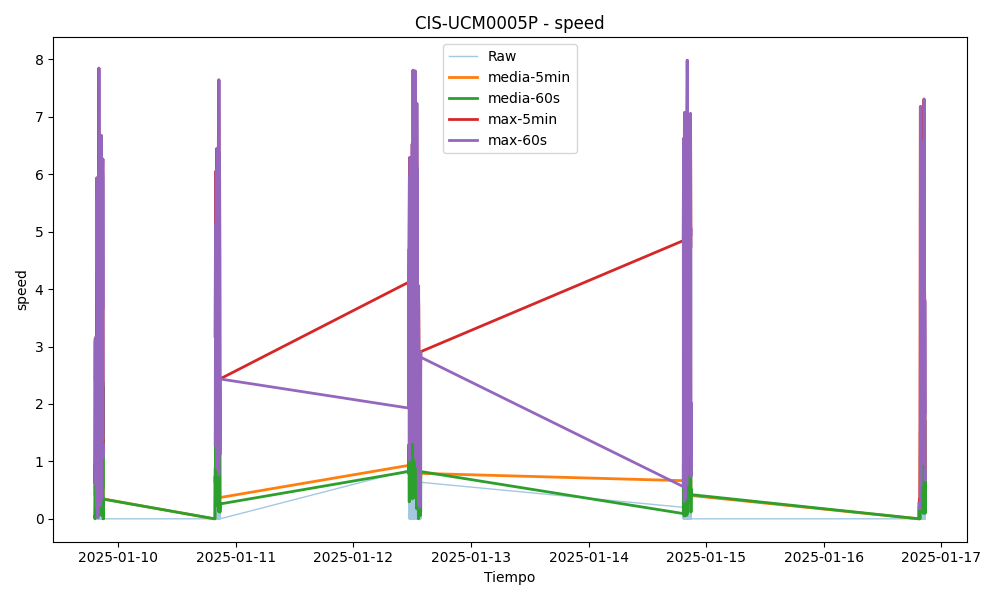

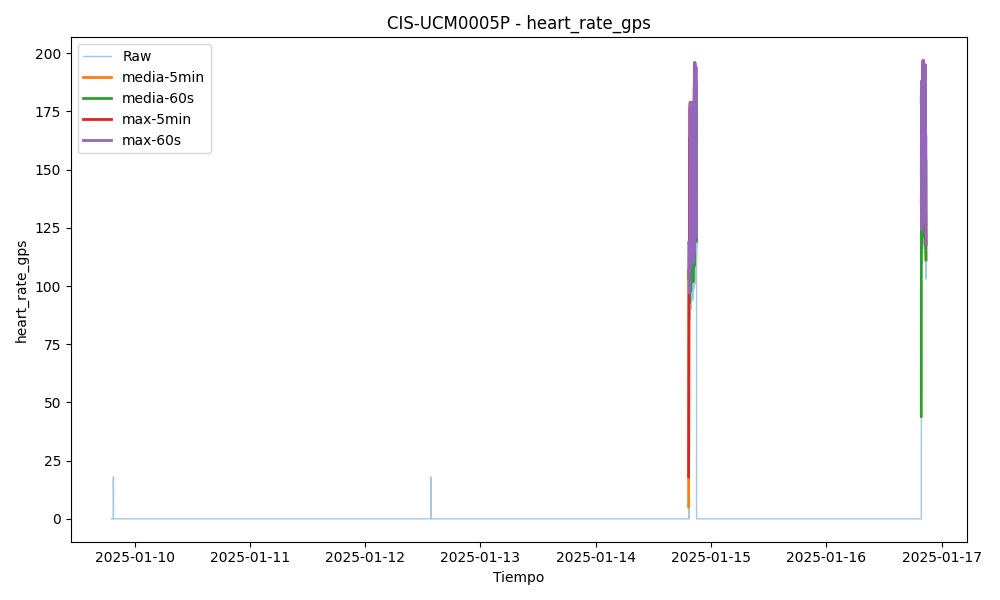

In [24]:
user_id = "CIS-UCM0005P"
variables = ['speed', 'heart_rate_gps']

for var in variables:
    graficar_participante(user_id, variable=var, 
                        metodos=['media', 'max'], 
                        intervalos=['5min', '60s'])


In [25]:
plt.close('all')

Graficamos los datos de las dispersiones existentes antes de agrupar los datos de los intervalos en un único valor.

In [26]:
def graficar_variaciones_gps(file_media, file_max, color_map=None, color_secundario="#960002", max_labels=5):
    """
    Grafica dos archivos de variaciones GPS (media y max) con colores personalizados,
    eje secundario para heart_rate_gps_var y eje x legible (equiespaciado y reducido).

    Args:
        file_media (str): Ruta al CSV de variaciones (ej: media).
        file_max (str): Ruta al CSV de variaciones (ej: max).
        color_map (dict, opcional): Diccionario de colores para variables principales.
        color_secundario (str, opcional): Color para heart_rate_gps_var (eje derecho).
        max_labels (int, opcional): Máximo número de labels a mostrar en el eje x.
    """
    if color_map is None:
        color_map = {
            'speed_var': "#ff41f9",
            'accX_var': "#0c004b",
            'accY_var': "#4f6ffc",
            'accZ_var': "#00d0ff",
            'latitude_var': "#052b00",
            'longitude_var': "#00ff59",
        }
    variables_primario = ['speed_var', 'accX_var', 'accY_var', 'accZ_var']
    variable_secundario = 'heart_rate_gps_var'

    def plot_variaciones(df, title):
        fig, ax1 = plt.subplots(figsize=(10, 6))
        for i, var in enumerate(variables_primario):
            if var in df.columns:
                color = color_map.get(var, f'C{i}')
                ax1.plot(df['time'], df[var], label=var, color=color, marker='')
        ax1.set_xlabel('Tiempo')
        ax1.set_ylabel('Variación')
        ax2 = ax1.twinx()
        if variable_secundario in df.columns:
            ax2.plot(df['time'], df[variable_secundario], label=variable_secundario,
                     color=color_secundario, marker='', alpha=0.7)
            ax2.set_ylabel(variable_secundario, color=color_secundario)
        ax1.set_title(title)
        ax1.legend(loc='upper left')

        # Eje x: equiespaciado
        n = len(df)
        if n > max_labels:
            step = max(1, n // max_labels)
            xticks = df['time'].iloc[::step]
            ax1.set_xticks(xticks)
        plt.xticks(rotation=90, ha='right')
        plt.tight_layout()
        plt.show()

    # Cargar y graficar MEDIA
    df_media = pd.read_csv(file_media)
    plot_variaciones(df_media, 'Variaciones GPS - 5min')

    # Cargar y graficar MAX
    df_max = pd.read_csv(file_max)
    plot_variaciones(df_max, 'Variaciones GPS - 60s')


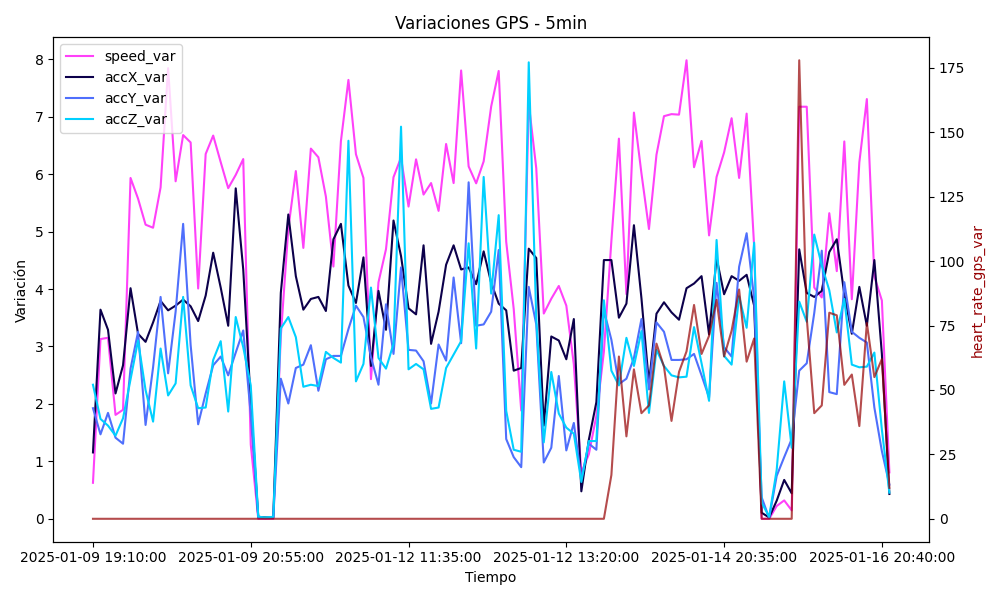

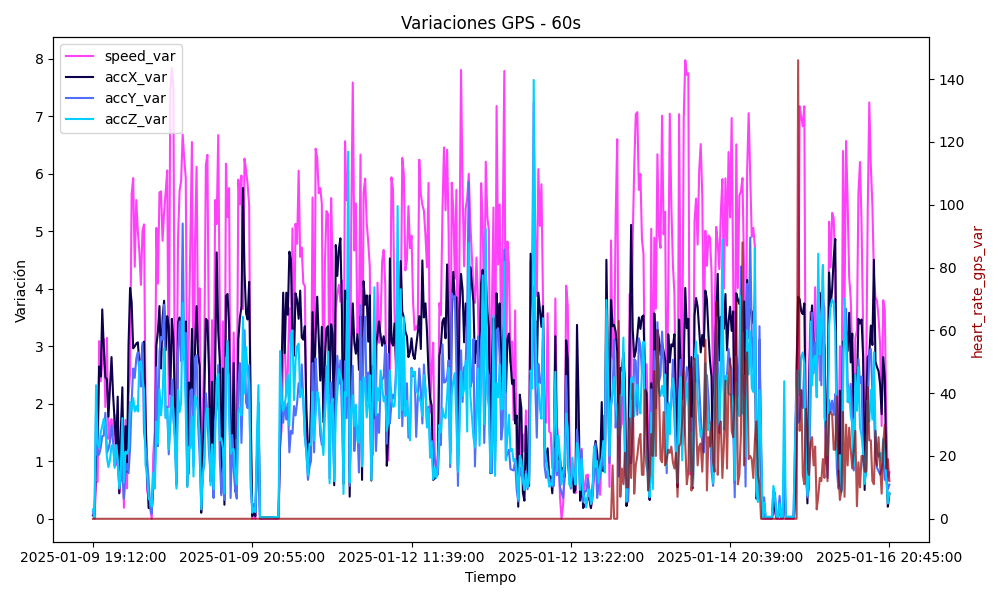

In [27]:
graficar_variaciones_gps(
    "Data/Staging/GPS/Variaciones/CIS-UCM0005P_5min_media_variaciones.csv",
    "Data/Staging/GPS/Variaciones/CIS-UCM0005P_60s_media_variaciones.csv"
)

In [28]:
plt.close('all')

Vemos que en algunos casos puntuales las grandes dispersiones existentes en los intervalos hacen que tomar el valor medio pueda no ser suficientemente representativo de los datos existentes en dicho intervalo.
Esto es algo que deberemos tener en cuenta si usamos estos datos agrupados.

### 3. Procesar datos staging a trusted

Finalmente, unimos en un único archivo por participante los datos de glucosa y GPS correspondientes.
Sólo creará un archivo trusted si hay tanto datos de glucosa como de GPS para el participante.

#### 3.1 Trusted completos

In [29]:
def resumen_diagnostico_trusted(df, user_id, resumen_path):
    """
    Genera y añade un resumen diagnóstico de nulos y ceros para las variables clave del archivo trusted.

    Args:
        df (pd.DataFrame): DataFrame fusionado trusted.
        user_id (str): Identificador del usuario.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.

    Returns:
        dict: Resumen diagnóstico generado.
    """
    variables = ["glucose", "heart_rate", "heart_rate_gps", "speed", "latitude", "longitude", "accX", "accY", "accZ"]
    resumen = {"user_id": user_id, "rows": len(df)}
    for var in variables:
        if var in df.columns:
            resumen[f"nulos_{var}"] = df[var].isna().sum()
            resumen[f"ceros_{var}"] = df[var][~df[var].isna()].eq(0).sum()
        else:
            resumen[f"nulos_{var}"] = None
            resumen[f"ceros_{var}"] = None
    if os.path.exists(resumen_path):
        df_resumen = pd.read_csv(resumen_path)
        df_resumen = df_resumen[df_resumen['user_id'] != user_id]
        df_resumen = pd.concat([df_resumen, pd.DataFrame([resumen])], ignore_index=True)
    else:
        df_resumen = pd.DataFrame([resumen])
    df_resumen.to_csv(resumen_path, index=False)
    print(f"Resumen diagnóstico añadido a {resumen_path}")
    return resumen

def fusionar_glucosa_gps_completo(archivo_glucosa, archivo_gps, destino_dir, resumen_path):
    """
    Fusiona archivos de glucosa y GPS completos para un usuario, manteniendo todos los registros de ambas fuentes.
    user_id y os son iguales en todo el archivo. exercise es 1 solo donde hay dato GPS, 0 en el resto.
    Genera un resumen diagnóstico final tras la fusión.

    Args:
        archivo_glucosa (str): Ruta al archivo de glucosa completo.
        archivo_gps (str): Ruta al archivo GPS completo.
        destino_dir (str): Carpeta donde guardar el archivo fusionado.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.

    Returns:
        pd.DataFrame: DataFrame combinado y guardado.
    """
    os.makedirs(destino_dir, exist_ok=True)
    user_id = os.path.basename(archivo_glucosa).split('_')[0].replace(".csv", "")

    # Cargar datos
    glucosa = pd.read_csv(archivo_glucosa, parse_dates=["time"])
    gps = pd.read_csv(archivo_gps, parse_dates=["time"])

    glucosa = glucosa.drop_duplicates(subset="time")
    gps = gps.drop_duplicates(subset="time")

    # Fusionar por outer join en 'time'
    combinado = pd.merge(glucosa, gps, on="time", how="outer", suffixes=("", "_gps"))

    # Limitar el índice temporal al rango de glucosa
    min_glucosa, max_glucosa = glucosa["time"].min(), glucosa["time"].max()
    combinado = combinado[(combinado["time"] >= min_glucosa) & (combinado["time"] <= max_glucosa)]

    # Ordenar por tiempo
    combinado = combinado.sort_values("time")

    # Eliminar columnas no deseadas si existen
    columnas_a_eliminar = ['basal_rate', 'bolus_volume_delivered', 'carb_input']
    combinado = combinado.drop(columns=[col for col in columnas_a_eliminar if col in combinado.columns], errors='ignore')

    # user_id: igual para todo el archivo
    combinado['user_id'] = user_id

    # os: igual para todo el archivo
    if 'os' in glucosa.columns:
        os_val = glucosa['os'].iloc[0]
    elif 'os' in gps.columns:
        os_val = gps['os'].iloc[0]
    else:
        os_val = 0
    combinado['os'] = os_val

    # exercise: 1 solo donde hay dato GPS (del archivo GPS), 0 en el resto
    if 'exercise' in combinado.columns:
        combinado['exercise'] = combinado['exercise'].fillna(0).astype(int)
    else:
        combinado['exercise'] = 0

    # Añadir columnas preferidas si faltan
    columnas_preferidas = [
        "time", "user_id", "glucose", "heart_rate", "heart_rate_gps", "os", "exercise"
    ]
    for col in columnas_preferidas:
        if col not in combinado.columns:
            combinado[col] = pd.NA

    # Ordenar columnas: preferidas + el resto
    otras_columnas = [c for c in combinado.columns if c not in columnas_preferidas]
    combinado = combinado[columnas_preferidas + otras_columnas]

    # Guardar (manteniendo máxima granularidad temporal)
    nombre_salida = f"{user_id}.csv"
    ruta_salida = os.path.join(destino_dir, nombre_salida)
    combinado.to_csv(ruta_salida, index=False)
    print(f"[OK] Guardado: {ruta_salida}")

    # Resumen diagnóstico final
    resumen_diagnostico_trusted(combinado, user_id, resumen_path)

    return combinado

def main():
    """
    Fusiona archivos completos de glucosa y GPS para todos los usuarios válidos,
    guardando solo si existen ambos archivos, y genera un resumen diagnóstico final.

    Returns:
        None
    """
    glucosa_5min_dir = "Data/Staging/Glucosa/*.csv"
    gps_completo_dir = "Data/Staging/GPS/Completos/*.csv"
    destino_dir = "Data/Trusted/Completos"
    resumen_path = "Data/resumen_diagnostico_trusted.csv"

    glucosa_5min_files = glob.glob(glucosa_5min_dir)
    gps_completo_files = glob.glob(gps_completo_dir)

    usuarios_validos = [
        "CIS-UCM0001P", "CIS-UCM0004P", "CIS-UCM0005P", "CIS-UCM0006P",
        "CIS-UCM0007P", "U10", "U12", "U13"
    ]

    for user_id in usuarios_validos:
        archivo_glucosa = next((file for file in glucosa_5min_files if user_id in file), None)
        archivo_gps = next((file for file in gps_completo_files if user_id in file), None)
        if archivo_glucosa and archivo_gps:
            fusionar_glucosa_gps_completo(archivo_glucosa, archivo_gps, destino_dir, resumen_path)

    print("Fusión de archivos completada.")

if __name__ == "__main__":
    main()


[OK] Guardado: Data/Trusted/Completos\CIS-UCM0005P.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted.csv
[OK] Guardado: Data/Trusted/Completos\CIS-UCM0006P.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted.csv
[OK] Guardado: Data/Trusted/Completos\CIS-UCM0007P.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted.csv
[OK] Guardado: Data/Trusted/Completos\U10.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted.csv
[OK] Guardado: Data/Trusted/Completos\U12.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted.csv
Fusión de archivos completada.


In [30]:
resumen_diagnostico_trusted_df = pd.read_csv("Data/resumen_diagnostico_trusted.csv")
resumen_diagnostico_trusted_df

,user_id,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,266500,264193,0,264193,0,187655,0,2299,38135,2299,0,2299,0,2299,0,2299,0,2299,0
1,CIS-UCM0006P,130855,128314,0,128314,0,7633,0,2536,5578,2536,0,2536,0,2536,0,2536,0,2536,0
2,CIS-UCM0007P,78911,78410,0,78410,0,3279,0,499,10536,499,0,499,0,499,0,499,0,499,0
3,U10,257376,253786,0,256396,0,82897,0,3964,50272,3964,0,3964,0,3964,0,3964,0,3964,0
4,U12,184788,182492,0,182514,0,25461,0,3198,39734,3198,0,3198,0,3198,0,3198,0,3198,0


##### Trusted completos forward-fill

Incluimos una versión de los mismos datos completos pero rellenando los NaNs de la variable de glucosa con el último datos disponible, sólo por si fuera de interés en algún momento futuro.

In [31]:
def fusionar_glucosa_gps_ffill(archivo_glucosa, archivo_gps, destino_dir, resumen_path):
    """
    Fusiona archivos de glucosa y GPS completos para un usuario, propagando los valores de glucosa
    hacia adelante (forward fill) en todas las columnas de glucosa salvo user_id, os, exercise.
    El archivo resultante se guarda en Trusted/Completos/Fill.

    Args:
        archivo_glucosa (str): Ruta al archivo de glucosa completo.
        archivo_gps (str): Ruta al archivo GPS completo.
        destino_dir (str): Carpeta donde guardar el archivo fusionado.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.

    Returns:
        pd.DataFrame: DataFrame combinado y guardado.
    """
    os.makedirs(destino_dir, exist_ok=True)
    user_id = os.path.basename(archivo_glucosa).split('_')[0].replace(".csv", "")

    # Cargar datos
    glucosa = pd.read_csv(archivo_glucosa, parse_dates=["time"])
    gps = pd.read_csv(archivo_gps, parse_dates=["time"])

    glucosa = glucosa.drop_duplicates(subset="time")
    gps = gps.drop_duplicates(subset="time")

    # Fusionar por outer join en 'time'
    combinado = pd.merge(glucosa, gps, on="time", how="outer", suffixes=("", "_gps"))
    combinado = combinado.sort_values("time")

    # Limitar el índice temporal al rango de glucosa
    min_glucosa, max_glucosa = glucosa["time"].min(), glucosa["time"].max()
    combinado = combinado[(combinado["time"] >= min_glucosa) & (combinado["time"] <= max_glucosa)]

    # user_id: igual para todo el archivo
    combinado['user_id'] = user_id

    # os: igual para todo el archivo
    if 'os' in glucosa.columns:
        os_val = glucosa['os'].iloc[0]
    elif 'os' in gps.columns:
        os_val = gps['os'].iloc[0]
    else:
        os_val = 0
    combinado['os'] = os_val

    # exercise: 1 solo donde hay dato GPS (del archivo GPS), 0 en el resto
    if 'exercise' in combinado.columns:
        combinado['exercise'] = combinado['exercise'].fillna(0).astype(int)
    else:
        combinado['exercise'] = 0

    # Forward fill para columnas de glucosa (excepto user_id, os, exercise y time)
    columnas_preferidas = [
        "time", "user_id", "glucose", "heart_rate", "heart_rate_gps", "os", "exercise"
    ]
    columnas_glucosa = [col for col in glucosa.columns if col not in ["time", "user_id", "os", "exercise"]]
    for col in columnas_glucosa:
        if col in combinado.columns:
            combinado[col] = combinado[col].ffill()

    # Eliminar columnas no deseadas si existen
    columnas_a_eliminar = ['basal_rate', 'bolus_volume_delivered', 'carb_input']
    combinado = combinado.drop(columns=[col for col in columnas_a_eliminar if col in combinado.columns], errors='ignore')

    # Ordenar columnas: preferidas + el resto
    otras_columnas = [c for c in combinado.columns if c not in columnas_preferidas]
    combinado = combinado[columnas_preferidas + otras_columnas]

    # Guardar (manteniendo máxima granularidad temporal)
    nombre_salida = f"{user_id}_ffill.csv"
    ruta_salida = os.path.join(destino_dir, nombre_salida)
    combinado.to_csv(ruta_salida, index=False)
    print(f"[OK] Guardado: {ruta_salida}")

    # Resumen diagnóstico final
    resumen_diagnostico_trusted(combinado, user_id, resumen_path)

    return combinado

def main():
    """
    Fusiona archivos completos de glucosa y GPS para todos los usuarios válidos,
    propagando los valores de glucosa hacia adelante (ffill) y generando un resumen diagnóstico final.

    Returns:
        None
    """
    glucosa_5min_dir = "Data/Staging/Glucosa/*.csv"
    gps_completo_dir = "Data/Staging/GPS/Completos/*.csv"
    destino_dir = "Data/Trusted/Completos/Fill"
    resumen_path = "Data/resumen_diagnostico_trusted_fill.csv"

    glucosa_5min_files = glob.glob(glucosa_5min_dir)
    gps_completo_files = glob.glob(gps_completo_dir)

    usuarios_validos = [
        "CIS-UCM0001P", "CIS-UCM0004P", "CIS-UCM0005P", "CIS-UCM0006P",
        "CIS-UCM0007P", "U10", "U12", "U13"
    ]

    for user_id in usuarios_validos:
        archivo_glucosa = next((file for file in glucosa_5min_files if user_id in file), None)
        archivo_gps = next((file for file in gps_completo_files if user_id in file), None)
        if archivo_glucosa and archivo_gps:
            fusionar_glucosa_gps_ffill(archivo_glucosa, archivo_gps, destino_dir, resumen_path)

    print("Fusión de archivos completada.")

if __name__ == "__main__":
    main()


[OK] Guardado: Data/Trusted/Completos/Fill\CIS-UCM0005P_ffill.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_fill.csv
[OK] Guardado: Data/Trusted/Completos/Fill\CIS-UCM0006P_ffill.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_fill.csv
[OK] Guardado: Data/Trusted/Completos/Fill\CIS-UCM0007P_ffill.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_fill.csv
[OK] Guardado: Data/Trusted/Completos/Fill\U10_ffill.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_fill.csv
[OK] Guardado: Data/Trusted/Completos/Fill\U12_ffill.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_fill.csv
Fusión de archivos completada.


Vemos los resúmenes diagnósticos en este caso.

In [32]:
resumen_diagnostico_trusted_fill_df = pd.read_csv("Data/resumen_diagnostico_trusted_fill.csv")
resumen_diagnostico_trusted_fill_df

,user_id,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,266500,0,0,0,0,187655,0,2299,38135,2299,0,2299,0,2299,0,2299,0,2299,0
1,CIS-UCM0006P,130855,0,0,0,0,7633,0,2536,5578,2536,0,2536,0,2536,0,2536,0,2536,0
2,CIS-UCM0007P,78911,0,0,0,0,3279,0,499,10536,499,0,499,0,499,0,499,0,499,0
3,U10,257376,17,0,0,0,82897,0,3964,50272,3964,0,3964,0,3964,0,3964,0,3964,0
4,U12,184788,616,0,9,0,25461,0,3198,39734,3198,0,3198,0,3198,0,3198,0,3198,0


##### Trusted completos con interpolación-fill

Como en el caso anterior, incluimos una versión de los mismos datos completos pero rellenando los NaNs de la variable de glucosa con un método de interpolación entre los datos extremos disponibles, sólo por si fuera de interés en algún momento futuro.

In [33]:
def resumen_diagnostico_trusted(df, user_id, resumen_path):
    """
    Genera y añade un resumen diagnóstico de nulos y ceros para las variables clave del archivo trusted.

    Args:
        df (pd.DataFrame): DataFrame fusionado trusted.
        user_id (str): Identificador del usuario.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.

    Returns:
        dict: Resumen diagnóstico generado.
    """
    variables = ["glucose", "heart_rate", "heart_rate_gps", "speed", "latitude", "longitude", "accX", "accY", "accZ"]
    resumen = {"user_id": user_id, "rows": len(df)}
    for var in variables:
        if var in df.columns:
            resumen[f"nulos_{var}"] = df[var].isna().sum()
            resumen[f"ceros_{var}"] = df[var][~df[var].isna()].eq(0).sum()
        else:
            resumen[f"nulos_{var}"] = None
            resumen[f"ceros_{var}"] = None
    if os.path.exists(resumen_path):
        df_resumen = pd.read_csv(resumen_path)
        df_resumen = df_resumen[df_resumen['user_id'] != user_id]
        df_resumen = pd.concat([df_resumen, pd.DataFrame([resumen])], ignore_index=True)
    else:
        df_resumen = pd.DataFrame([resumen])
    df_resumen.to_csv(resumen_path, index=False)
    print(f"Resumen diagnóstico añadido a {resumen_path}")
    return resumen

def fusionar_glucosa_gps_interpolado(archivo_glucosa, archivo_gps, destino_dir, resumen_path):
    """
    Fusiona archivos de glucosa y GPS completos para un usuario, manteniendo todos los registros de ambas fuentes.
    user_id y os son iguales en todo el archivo. exercise es 1 solo donde hay dato GPS, 0 en el resto.
    Rellena las variables de glucosa (excepto user_id, os, exercise) usando interpolación temporal.
    Genera un resumen diagnóstico final tras la fusión.

    Args:
        archivo_glucosa (str): Ruta al archivo de glucosa completo.
        archivo_gps (str): Ruta al archivo GPS completo.
        destino_dir (str): Carpeta donde guardar el archivo fusionado.
        resumen_path (str): Ruta del CSV de resumen diagnóstico.

    Returns:
        pd.DataFrame: DataFrame combinado y guardado.
    """
    os.makedirs(destino_dir, exist_ok=True)
    user_id = os.path.basename(archivo_glucosa).split('_')[0].replace(".csv", "")

    # Cargar datos
    glucosa = pd.read_csv(archivo_glucosa, parse_dates=["time"])
    gps = pd.read_csv(archivo_gps, parse_dates=["time"])

    glucosa = glucosa.drop_duplicates(subset="time")
    gps = gps.drop_duplicates(subset="time")

    # Fusionar por outer join en 'time'
    combinado = pd.merge(glucosa, gps, on="time", how="outer", suffixes=("", "_gps"))
    combinado = combinado.sort_values("time")

    # Limitar el índice temporal al rango de glucosa
    min_glucosa, max_glucosa = glucosa["time"].min(), glucosa["time"].max()
    combinado = combinado[(combinado["time"] >= min_glucosa) & (combinado["time"] <= max_glucosa)]

    # user_id: igual para todo el archivo
    combinado['user_id'] = user_id

    # os: igual para todo el archivo
    if 'os' in glucosa.columns:
        os_val = glucosa['os'].iloc[0]
    elif 'os' in gps.columns:
        os_val = gps['os'].iloc[0]
    else:
        os_val = 0
    combinado['os'] = os_val

    # exercise: 1 solo donde hay dato GPS (del archivo GPS), 0 en el resto
    if 'exercise' in combinado.columns:
        combinado['exercise'] = combinado['exercise'].fillna(0).astype(int)
    else:
        combinado['exercise'] = 0

    # Interpolación temporal en variables de glucosa (excepto user_id, os, exercise, time)
    columnas_preferidas = [
        "time", "user_id", "glucose", "heart_rate", "heart_rate_gps", "os", "exercise"
    ]
    columnas_glucosa = [col for col in glucosa.columns if col not in ["time", "user_id", "os", "exercise"]]
    combinado = combinado.set_index('time')
    for col in columnas_glucosa:
        if col in combinado.columns:
            combinado[col] = combinado[col].interpolate(method='time')
    combinado = combinado.reset_index()

    # Eliminar columnas no deseadas si existen
    columnas_a_eliminar = ['basal_rate', 'bolus_volume_delivered', 'carb_input']
    combinado = combinado.drop(columns=[col for col in columnas_a_eliminar if col in combinado.columns], errors='ignore')

    # Ordenar columnas: preferidas + el resto
    otras_columnas = [c for c in combinado.columns if c not in columnas_preferidas]
    combinado = combinado[columnas_preferidas + otras_columnas]

    # Guardar (manteniendo máxima granularidad temporal)
    nombre_salida = f"{user_id}_interpol.csv"
    ruta_salida = os.path.join(destino_dir, nombre_salida)
    combinado.to_csv(ruta_salida, index=False)
    print(f"[OK] Guardado: {ruta_salida}")

    # Resumen diagnóstico final
    resumen_diagnostico_trusted(combinado, user_id, resumen_path)

    return combinado

def main():
    """
    Fusiona archivos completos de glucosa y GPS para todos los usuarios válidos,
    interpolando las variables de glucosa en los huecos, y generando un resumen diagnóstico final.

    Returns:
        None
    """
    glucosa_5min_dir = "Data/Staging/Glucosa/*.csv"
    gps_completo_dir = "Data/Staging/GPS/Completos/*.csv"
    destino_dir = "Data/Trusted/Completos/Interpol"
    resumen_path = "Data/resumen_diagnostico_trusted_interpol.csv"

    glucosa_5min_files = glob.glob(glucosa_5min_dir)
    gps_completo_files = glob.glob(gps_completo_dir)

    usuarios_validos = [
        "CIS-UCM0001P", "CIS-UCM0004P", "CIS-UCM0005P", "CIS-UCM0006P",
        "CIS-UCM0007P", "U10", "U12", "U13"
    ]

    for user_id in usuarios_validos:
        archivo_glucosa = next((file for file in glucosa_5min_files if user_id in file), None)
        archivo_gps = next((file for file in gps_completo_files if user_id in file), None)
        if archivo_glucosa and archivo_gps:
            fusionar_glucosa_gps_interpolado(archivo_glucosa, archivo_gps, destino_dir, resumen_path)

    print("Fusión de archivos completada (interpolado).")

if __name__ == "__main__":
    main()


[OK] Guardado: Data/Trusted/Completos/Interpol\CIS-UCM0005P_interpol.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_interpol.csv
[OK] Guardado: Data/Trusted/Completos/Interpol\CIS-UCM0006P_interpol.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_interpol.csv
[OK] Guardado: Data/Trusted/Completos/Interpol\CIS-UCM0007P_interpol.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_interpol.csv
[OK] Guardado: Data/Trusted/Completos/Interpol\U10_interpol.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_interpol.csv
[OK] Guardado: Data/Trusted/Completos/Interpol\U12_interpol.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_interpol.csv
Fusión de archivos completada (interpolado).


Vemos el resumen diagnóstico de este caso.

In [34]:
resumen_diagnostico_trusted_interpol_df = pd.read_csv("Data/resumen_diagnostico_trusted_interpol.csv")
resumen_diagnostico_trusted_interpol_df

,user_id,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,nulos_heart_rate_gps,ceros_heart_rate_gps,nulos_speed,ceros_speed,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,266500,0,0,0,0,187655,0,2299,38135,2299,0,2299,0,2299,0,2299,0,2299,0
1,CIS-UCM0006P,130855,0,0,0,0,7633,0,2536,5578,2536,0,2536,0,2536,0,2536,0,2536,0
2,CIS-UCM0007P,78911,0,0,0,0,3279,0,499,10536,499,0,499,0,499,0,499,0,499,0
3,U10,257376,17,0,0,0,82897,0,3964,50272,3964,0,3964,0,3964,0,3964,0,3964,0
4,U12,184788,616,0,9,0,25461,0,3198,39734,3198,0,3198,0,3198,0,3198,0,3198,0


#### 3.2 Trusted agrupados

De igual forma, creamos un archivo trusted único con los datos agrupados cada 60 segundos o 5 minutos.

In [35]:
def resumen_diagnostico_trusted(df, user_id, intervalo, metodo, resumen_path):
    """
    Genera y añade un resumen diagnóstico de nulos y ceros para las variables clave del archivo trusted.

    Args:
        df (pd.DataFrame): DataFrame fusionado trusted.
        user_id (str): Identificador del usuario.
        intervalo (str): Intervalo de agrupación (ej: '60s', '5min').
        metodo (str): Método de agregación ('media', 'max').
        resumen_path (str): Ruta del CSV de resumen diagnóstico.

    Returns:
        dict: Resumen diagnóstico generado.
    """
    variables = ["glucose", "heart_rate", "heart_rate_gps", "speed", "latitude", "longitude", "accX", "accY", "accZ"]
    resumen = {"user_id": user_id, "intervalo": intervalo, "metodo": metodo, "rows": len(df)}
    for var in variables:
        if var in df.columns:
            resumen[f"nulos_{var}"] = df[var].isna().sum()
            resumen[f"ceros_{var}"] = df[var][~df[var].isna()].eq(0).sum()
        else:
            resumen[f"nulos_{var}"] = None
            resumen[f"ceros_{var}"] = None
    if os.path.exists(resumen_path):
        df_resumen = pd.read_csv(resumen_path)
        df_resumen = df_resumen[
            ~((df_resumen['user_id'] == user_id) & (df_resumen['intervalo'] == intervalo) & (df_resumen['metodo'] == metodo))
        ]
        df_resumen = pd.concat([df_resumen, pd.DataFrame([resumen])], ignore_index=True)
    else:
        df_resumen = pd.DataFrame([resumen])
    df_resumen.to_csv(resumen_path, index=False)
    print(f"Resumen diagnóstico añadido a {resumen_path}")
    return resumen

def fusionar_glucosa_gps_agrupado(archivo_glucosa, archivo_gps, destino_dir, resumen_path):
    """
    Fusiona archivos de glucosa y GPS agrupados, manteniendo todos los registros de glucosa (rejilla temporal).
    user_id y os son iguales en todo el archivo. exercise es 1 solo donde hay dato GPS, 0 en el resto.
    Genera un resumen diagnóstico final tras la fusión.

    Args:
        archivo_glucosa (str): Ruta al archivo de glucosa agrupada.
        archivo_gps (str): Ruta al archivo GPS agrupado.
        destino_dir (str): Carpeta donde guardar el archivo fusionado.
        resumen_path (str): Ruta del CSV del resumen diagnóstico.

    Returns:
        pd.DataFrame: DataFrame combinado y guardado.
    """
    os.makedirs(destino_dir, exist_ok=True)
    base_gps = os.path.basename(archivo_gps)
    patron = r"(.+?)_(\d+)(min|s)_(max|media)\.csv"
    match = re.match(patron, base_gps)
    if match:
        user_id, intervalo, unidad, metodo = match.groups()
        intervalo_str = f"{intervalo}{unidad}"
    else:
        print(f"[ADVERTENCIA] No se pudo extraer intervalo y método del nombre: {base_gps}")
        user_id = os.path.splitext(base_gps)[0]
        intervalo_str = "NA"
        metodo = "NA"

    glucosa = pd.read_csv(archivo_glucosa, parse_dates=["time"])
    gps = pd.read_csv(archivo_gps, parse_dates=["time"])
    glucosa = glucosa.drop_duplicates(subset="time")
    gps = gps.drop_duplicates(subset="time")

    combinado = pd.merge(glucosa, gps, on="time", how="left", suffixes=("", "_gps"))

    columnas_a_eliminar = ['basal_rate', 'bolus_volume_delivered', 'carb_input']
    combinado = combinado.drop(columns=[col for col in columnas_a_eliminar if col in combinado.columns], errors='ignore')

    # user_id: igual para todo el archivo
    combinado['user_id'] = user_id

    # os: igual para todo el archivo
    if 'os' in glucosa.columns:
        os_val = glucosa['os'].iloc[0]
    elif 'os' in gps.columns:
        os_val = gps['os'].iloc[0]
    else:
        os_val = 0
    combinado['os'] = os_val

    # exercise: 1 solo donde hay dato GPS (del archivo GPS), 0 en el resto
    if 'exercise' in combinado.columns:
        combinado['exercise'] = combinado['exercise'].fillna(0).astype(int)
    else:
        combinado['exercise'] = 0

    columnas_preferidas = [
        "time", "user_id", "glucose", "heart_rate", "heart_rate_gps", "os", "exercise"
    ]
    for col in columnas_preferidas:
        if col not in combinado.columns:
            combinado[col] = pd.NA

    otras_columnas = [c for c in combinado.columns if c not in columnas_preferidas]
    combinado = combinado[columnas_preferidas + otras_columnas]

    nombre_salida = f"{user_id}_{intervalo_str}_{metodo}.csv"
    ruta_salida = os.path.join(destino_dir, nombre_salida)
    combinado.to_csv(ruta_salida, index=False)
    print(f"[OK] Guardado: {ruta_salida}")

    resumen_diagnostico_trusted(combinado, user_id, intervalo_str, metodo, resumen_path)

    return combinado

def main():
    """
    Fusiona archivos agrupados de glucosa y GPS para todos los usuarios y combinaciones de intervalo/método,
    guardando solo si existen ambos archivos, y genera un resumen diagnóstico final único.

    Returns:
        None

    Ejemplo:
        >>> main()
    """
    destino_dir = "Data/Trusted/Agrupados"
    resumen_path = "Data/resumen_diagnostico_trusted_agrupados.csv"
    glucosa_5min_dir = "Data/Staging/Glucosa/*.csv"
    glucosa_60s_dir = "Data/Staging/Glucosa/Glucosa extendida/*.csv"
    gps_5min_dir = "Data/Staging/GPS/Agrupados/*_5min_*.csv"
    gps_60s_dir = "Data/Staging/GPS/Agrupados/*_60s_*.csv"

    glucosa_5min_files = glob.glob(glucosa_5min_dir)
    glucosa_60s_files = glob.glob(glucosa_60s_dir)
    gps_5min_files = glob.glob(gps_5min_dir)
    gps_60s_files = glob.glob(gps_60s_dir)

    usuarios_validos = [
        "CIS-UCM0001P", "CIS-UCM0004P", "CIS-UCM0005P", "CIS-UCM0006P",
        "CIS-UCM0007P", "U10", "U12", "U13"
    ]

    usuarios = {}
    for user_id in usuarios_validos:
        usuarios[user_id] = {'glucosa_5min': None, 'glucosa_60s': None, 'gps_5min': None, 'gps_5min_max': None, 'gps_60s': None, 'gps_60s_max': None}
        for archivo in glucosa_5min_files:
            if user_id in archivo:
                usuarios[user_id]['glucosa_5min'] = archivo
        for archivo in glucosa_60s_files:
            if user_id in archivo:
                usuarios[user_id]['glucosa_60s'] = archivo
        for archivo in gps_5min_files:
            if user_id in archivo:
                if 'media' in archivo:
                    usuarios[user_id]['gps_5min'] = archivo
                elif 'max' in archivo:
                    usuarios[user_id]['gps_5min_max'] = archivo
        for archivo in gps_60s_files:
            if user_id in archivo:
                if 'media' in archivo:
                    usuarios[user_id]['gps_60s'] = archivo
                elif 'max' in archivo:
                    usuarios[user_id]['gps_60s_max'] = archivo

    for user_id, files in usuarios.items():
        if files['glucosa_5min']:
            if files['gps_5min']:
                fusionar_glucosa_gps_agrupado(files['glucosa_5min'], files['gps_5min'], destino_dir, resumen_path)
            if files['gps_5min_max']:
                fusionar_glucosa_gps_agrupado(files['glucosa_5min'], files['gps_5min_max'], destino_dir, resumen_path)
        if files['glucosa_60s']:
            if files['gps_60s']:
                fusionar_glucosa_gps_agrupado(files['glucosa_60s'], files['gps_60s'], destino_dir, resumen_path)
            if files['gps_60s_max']:
                fusionar_glucosa_gps_agrupado(files['glucosa_60s'], files['gps_60s_max'], destino_dir, resumen_path)

    print("Fusión de archivos agrupados completada.")

if __name__ == "__main__":
    main()


[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0005P_5min_media.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0005P_5min_max.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0005P_60s_media.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0005P_60s_max.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0006P_5min_media.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0006P_5min_max.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Guardado: Data/Trusted/Agrupados\CIS-UCM0006P_60s_media.csv
Resumen diagnóstico añadido a Data/resumen_diagnostico_trusted_agrupados.csv
[OK] Gua

Comprobamos su resumen diagnóstico.

In [36]:
resumen_diagnostico_trusted_agrupados = pd.read_csv("Data/resumen_diagnostico_trusted_agrupados.csv")
resumen_diagnostico_trusted_agrupados

,user_id,intervalo,metodo,rows,nulos_glucose,ceros_glucose,nulos_heart_rate,ceros_heart_rate,nulos_heart_rate_gps,ceros_heart_rate_gps,...,nulos_latitude,ceros_latitude,nulos_longitude,ceros_longitude,nulos_accX,ceros_accX,nulos_accY,ceros_accY,nulos_accZ,ceros_accZ
0,CIS-UCM0005P,5min,media,2307,0,0,0,0,2272,0,...,2200,0,2200,0,2200,0,2200,0,2200,0
1,CIS-UCM0005P,5min,max,2307,0,0,0,0,2272,0,...,2200,0,2200,0,2200,0,2200,0,2200,0
2,CIS-UCM0005P,60s,media,11531,0,0,0,0,11375,0,...,11015,0,11015,0,11015,0,11015,0,11015,0
3,CIS-UCM0005P,60s,max,11531,0,0,0,0,11375,0,...,11015,0,11015,0,11015,0,11015,0,11015,0
4,CIS-UCM0006P,5min,media,2541,0,0,0,0,2490,0,...,2490,0,2490,0,2490,0,2490,0,2490,0
5,CIS-UCM0006P,5min,max,2541,0,0,0,0,2490,0,...,2490,0,2490,0,2490,0,2490,0,2490,0
6,CIS-UCM0006P,60s,media,12706,0,0,0,0,12467,0,...,12461,0,12461,0,12461,0,12461,0,12461,0
7,CIS-UCM0006P,60s,max,12706,0,0,0,0,12467,0,...,12461,0,12461,0,12461,0,12461,0,12461,0
8,CIS-UCM0007P,5min,media,501,0,0,0,0,471,0,...,470,0,470,0,470,0,470,0,470,0
9,CIS-UCM0007P,5min,max,501,0,0,0,0,471,0,...,470,0,470,0,470,0,470,0,470,0


#### 3.3 Gráficas trusted

Para graficar adecuadamente los datos debemos aplicamos un filtro sobre ceros y los NaNs, para evitar problemas con ventanas temporales que puedan quedarse sin graficar.

Incluiremos un sombreado que muestre los momentos de ejercicio y una ventana posterior (8 horas por defecto).

In [37]:
def graficar_glucosa_hr_trusted(
    archivo_master,
    titulo=None,
    sombrear_ejercicio=True,
    sombrear_postejercicio_horas=8,
    figsize=(10, 6)
):
    """
    Grafica glucosa, heart_rate y heart_rate_gps de un archivo trusted, filtrando ceros y NaNs,
    y sombreando los bloques continuos de ejercicio (gris) y el post-ejercicio (gris claro).

    Args:
        archivo_master (str): Ruta al archivo trusted del usuario.
        titulo (str, opcional): Título del gráfico. Si None, usa el nombre del archivo.
        sombrear_ejercicio (bool, opcional): Si True, añade sombreado en periodos de ejercicio.
        sombrear_postejercicio_horas (int, opcional): Horas a sombrear tras cada bloque de ejercicio.
        figsize (tuple, opcional): Tamaño de la figura.

    Returns:
        None
    """
    master = pd.read_csv(archivo_master, parse_dates=['time'])

    for col in ['glucose', 'heart_rate', 'heart_rate_gps']:
        if col in master.columns:
            master[col] = master[col].astype(float)

    fig, ax1 = plt.subplots(figsize=figsize)

    # Sombrear bloques de ejercicio y post-ejercicio, y guardar handles para la leyenda
    legend_handles = []
    if sombrear_ejercicio and 'exercise' in master.columns:
        master = master.sort_values('time')
        mask = (master['exercise'] == 1)
        mask_shift = mask.shift(1, fill_value=False)
        start_blocks = master['time'][(mask) & (~mask_shift)].reset_index(drop=True)
        end_blocks = master['time'][(mask_shift) & (~mask)].reset_index(drop=True)
        if len(end_blocks) < len(start_blocks):
            end_blocks = pd.concat([end_blocks, pd.Series(master['time'].iloc[-1:])]).reset_index(drop=True)
        for start, end in zip(start_blocks, end_blocks):
            ax1.axvspan(start, end, color='gray', alpha=0.2)
            post_end = end + pd.Timedelta(hours=sombrear_postejercicio_horas)
            ax1.axvspan(end, post_end, color='lightgray', alpha=0.15)
        legend_handles.append(mpatches.Patch(color='gray', alpha=0.2, label='Ejercicio'))
        legend_handles.append(mpatches.Patch(color='lightgray', alpha=0.15, label=f'Post-ejercicio: {sombrear_postejercicio_horas}h'))

    # Glucosa (sin ceros ni NaN)
    if 'glucose' in master.columns:
        glucose_filtered = master[(master['glucose'] != 0) & (~master['glucose'].isna())]
        line_glucose, = ax1.plot(glucose_filtered['time'], glucose_filtered['glucose'], color='tab:blue', label='Glucosa')
        ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.set_xlabel('Tiempo')

    # Heart Rate y Heart Rate GPS (sin ceros ni NaN)
    ax2 = ax1.twinx()
    lines_hr = []
    if 'heart_rate' in master.columns:
        heart_rate_filtered = master[(master['heart_rate'] != 0) & (~master['heart_rate'].isna())]
        line_hr, = ax2.plot(heart_rate_filtered['time'], heart_rate_filtered['heart_rate'], color='tab:red', alpha=0.6, label='Heart Rate')
        lines_hr.append(line_hr)
    if 'heart_rate_gps' in master.columns:
        heart_rate_gps_filtered = master[(master['heart_rate_gps'] != 0) & (~master['heart_rate_gps'].isna())]
        line_hrgps, = ax2.plot(heart_rate_gps_filtered['time'], heart_rate_gps_filtered['heart_rate_gps'], color='orange', alpha=0.6, linestyle='dashed', label='Heart Rate GPS')
        lines_hr.append(line_hrgps)
    ax2.set_ylabel('Heart Rate', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Leyenda combinada
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    handles = lines1 + lines_hr + legend_handles
    labels = labels1 + labels2 + [h.get_label() for h in legend_handles]
    ax2.legend(handles, labels, loc='upper left')

    # Título con el nombre del archivo si no se pasa explícito
    if titulo is None:
        nombre_archivo = os.path.basename(archivo_master).replace('.csv', '')
        titulo = f"{nombre_archivo} - Glucosa, Heart Rate y Heart Rate GPS vs Tiempo"
    plt.title(titulo)
    fig.tight_layout()
    plt.show()


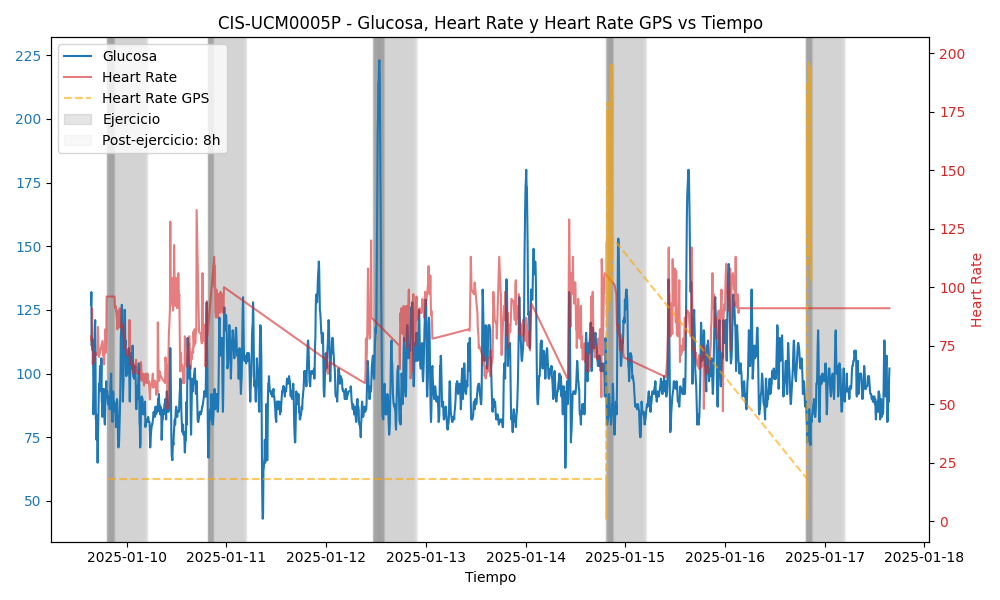

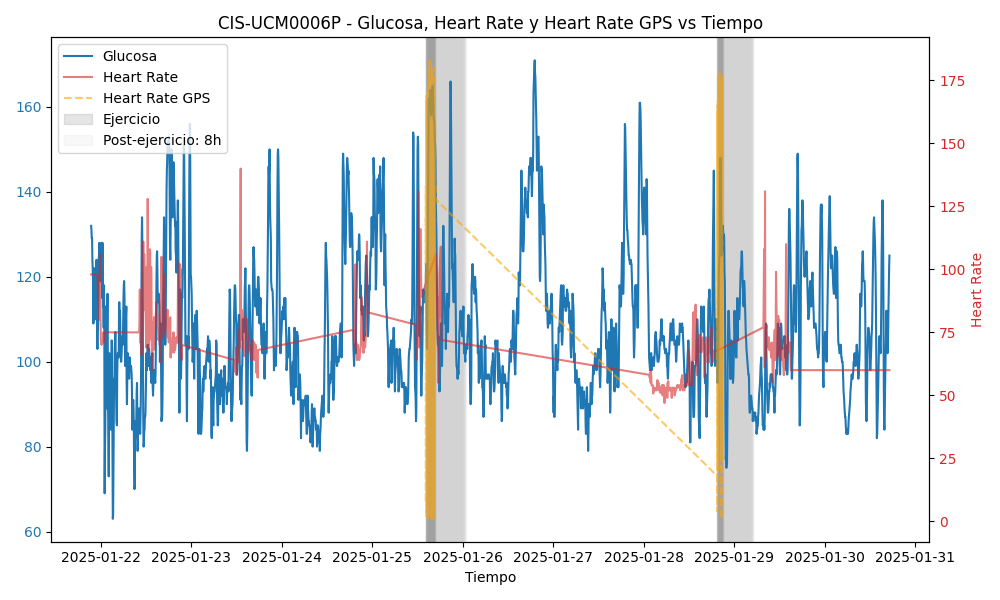

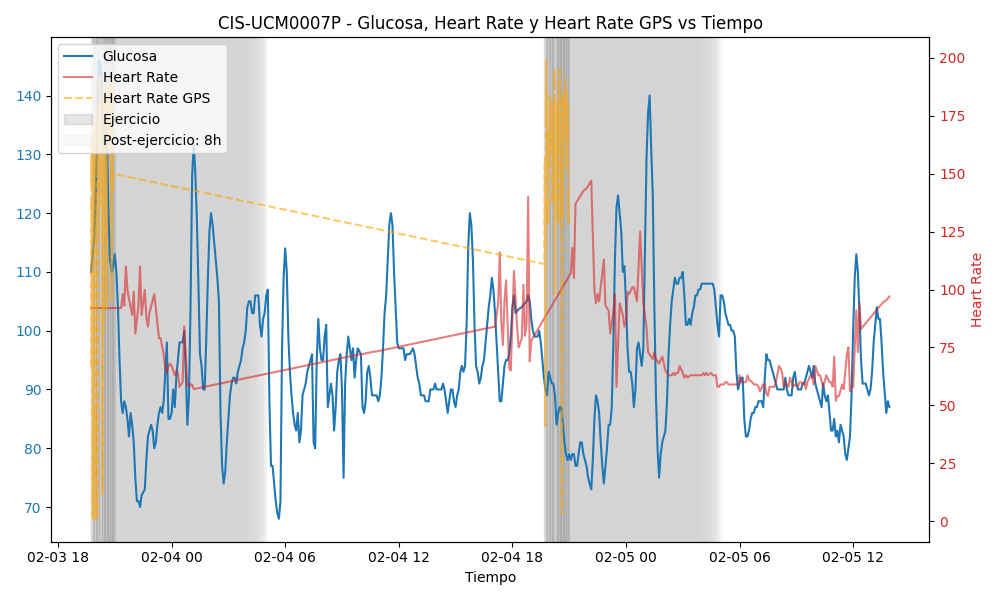

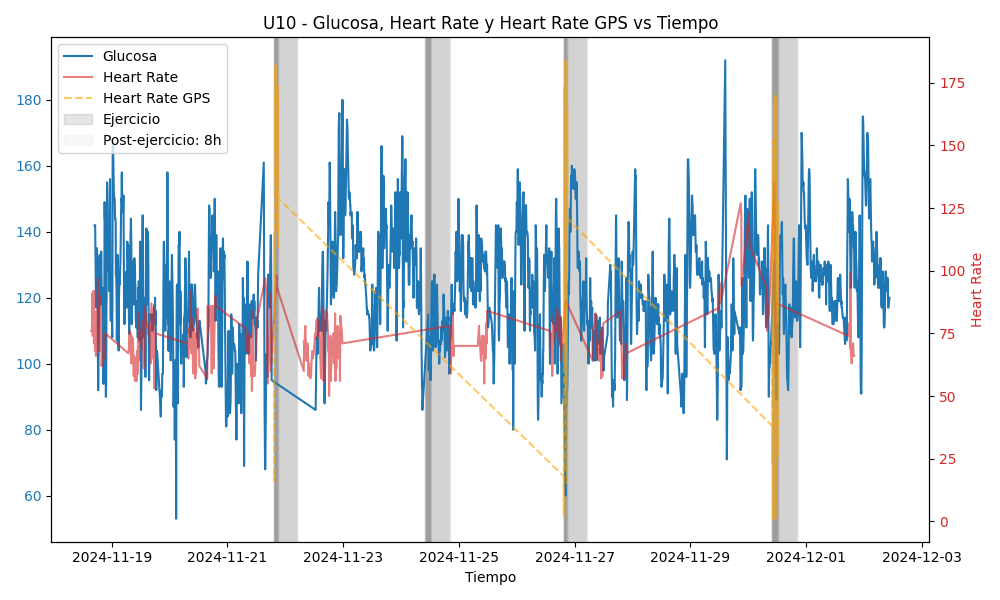

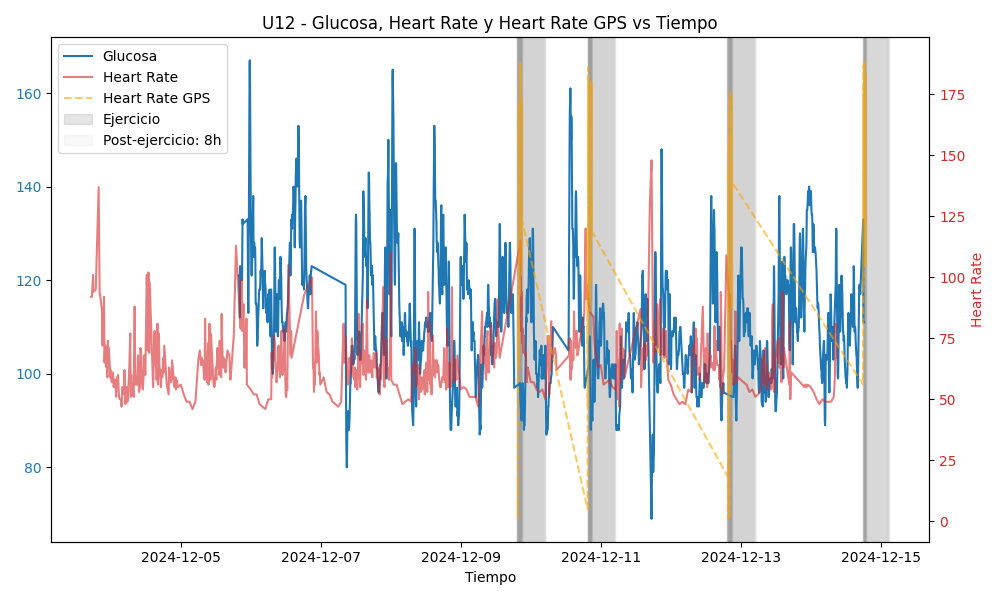

In [38]:
# GRÁFICAS DE DATOS COMPLETOS

files = glob.glob("Data/Trusted/Completos/*.csv")
for archivo in files:
    graficar_glucosa_hr_trusted(archivo)

In [39]:
plt.close('all')

Aunque hemos puesto un filtro de NaNs y 0 a estas variables, aún hay datos con valor numérico muy bajo (1.5, 1...) que pasan este filtro y por eso aún aparecen en las gráficas.

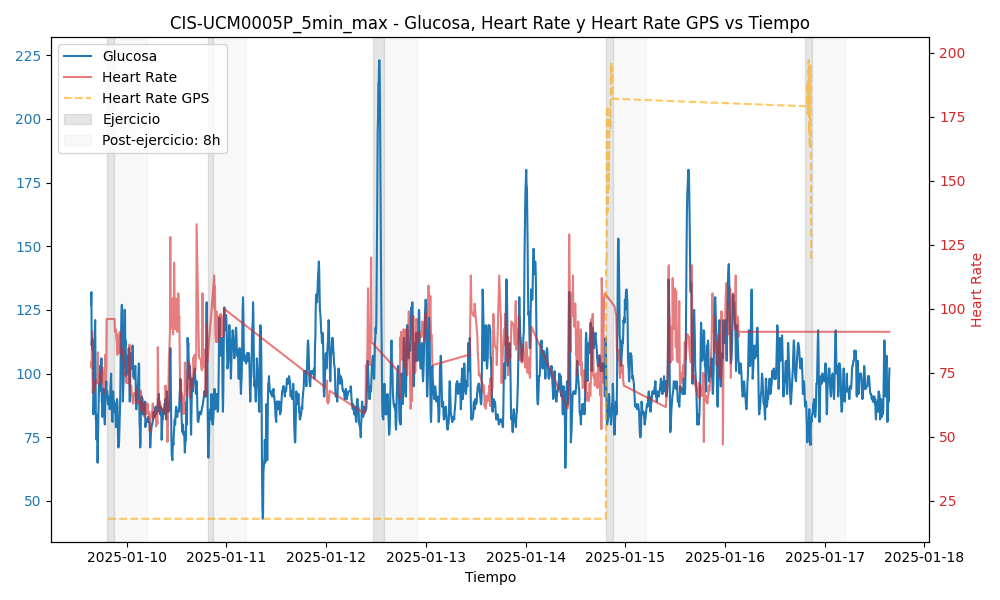

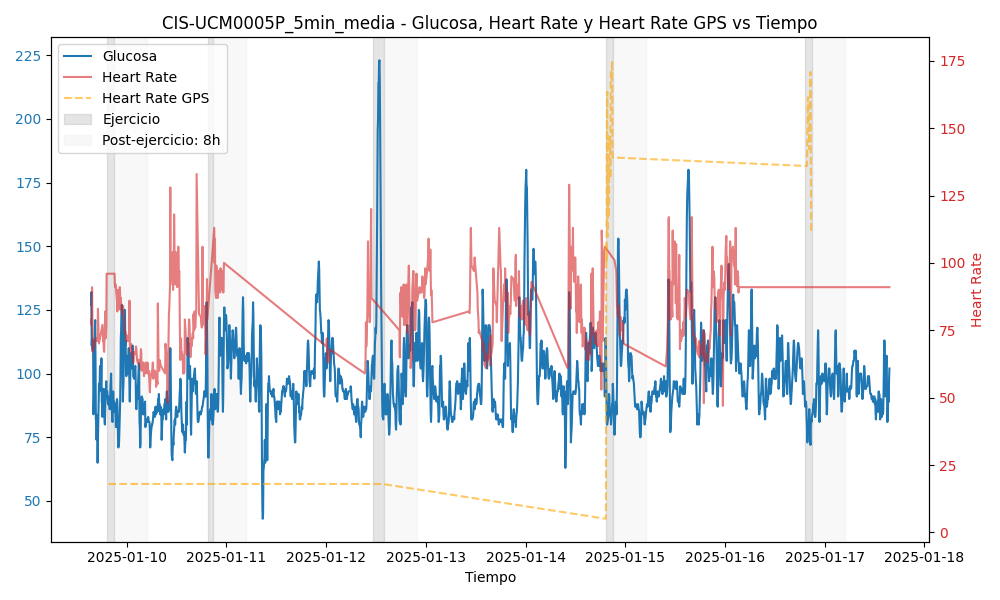

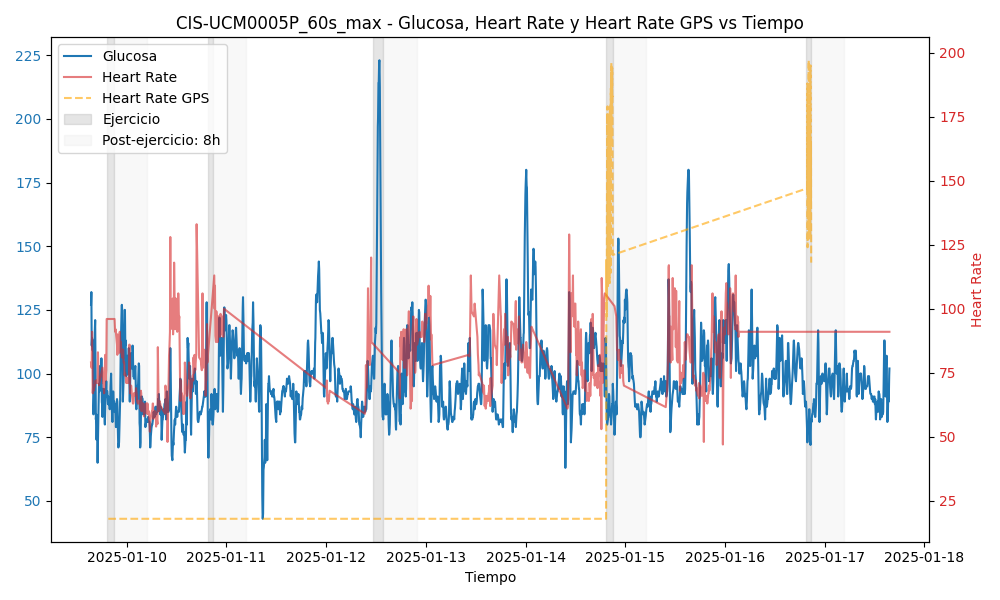

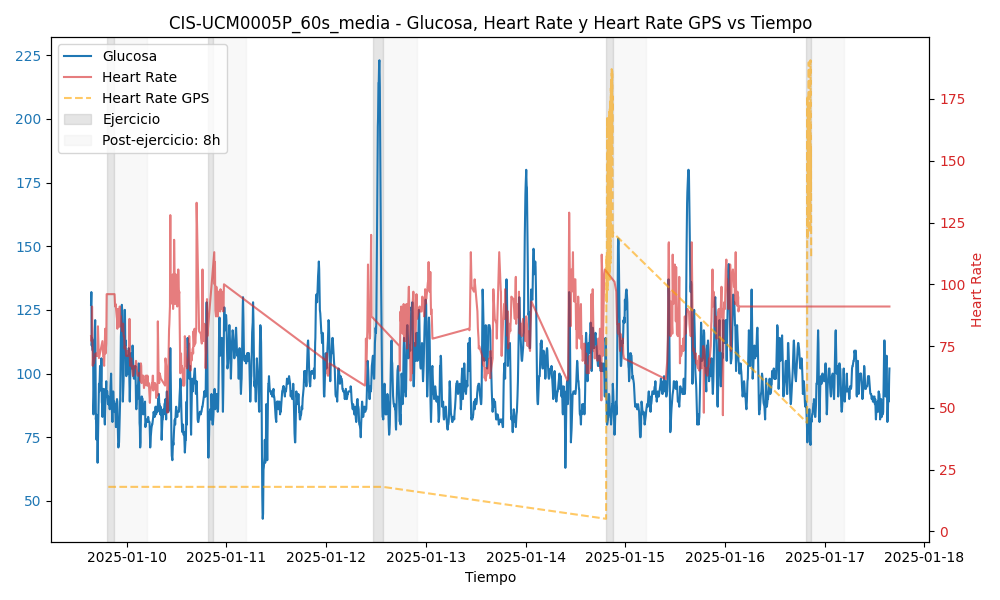

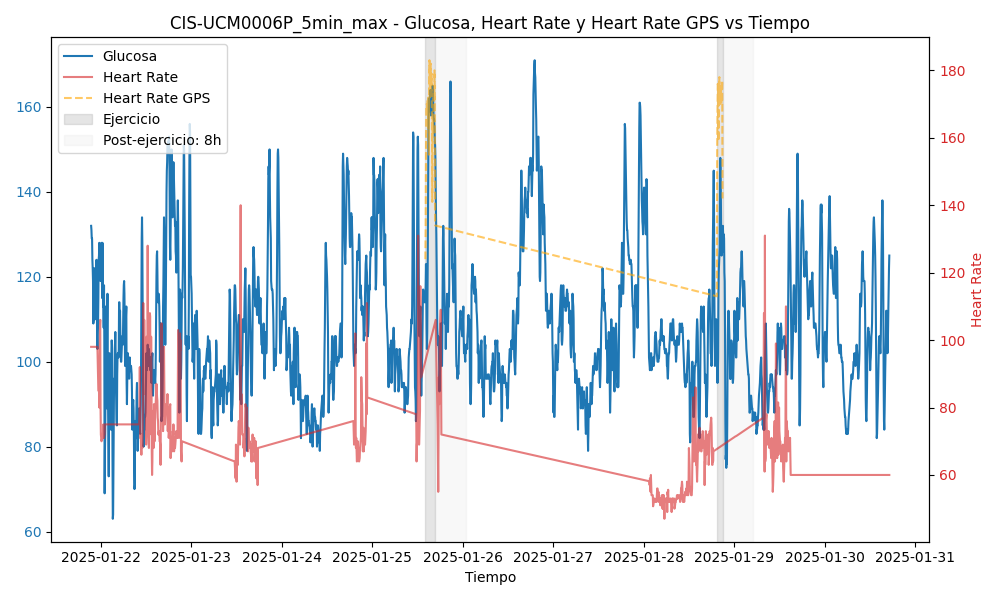

...

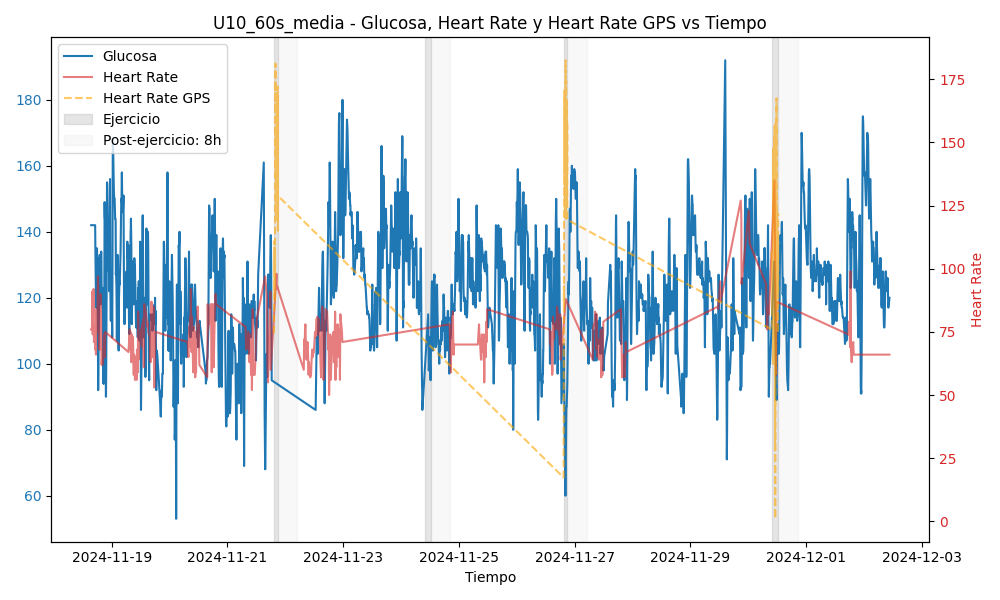

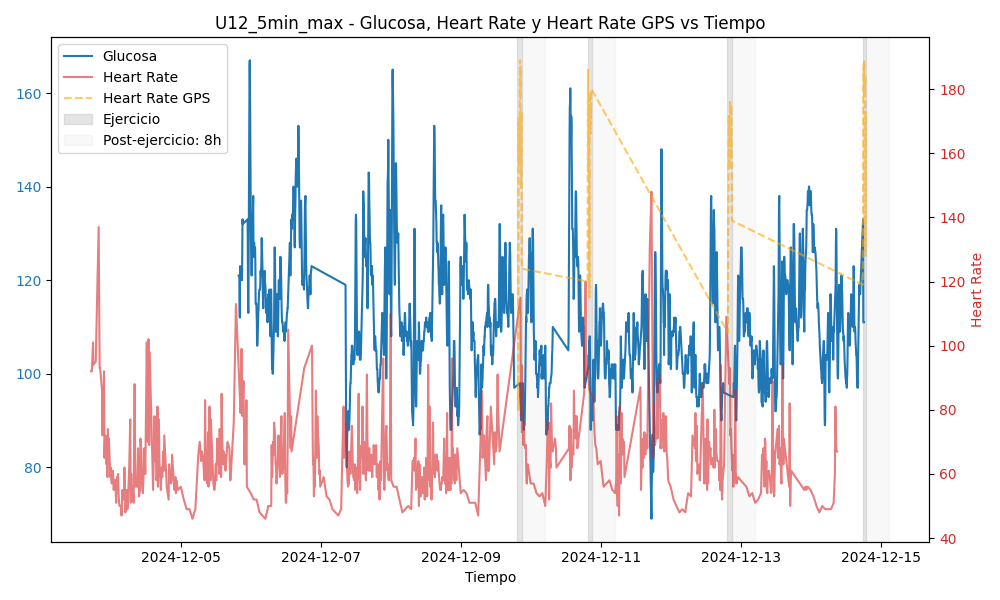

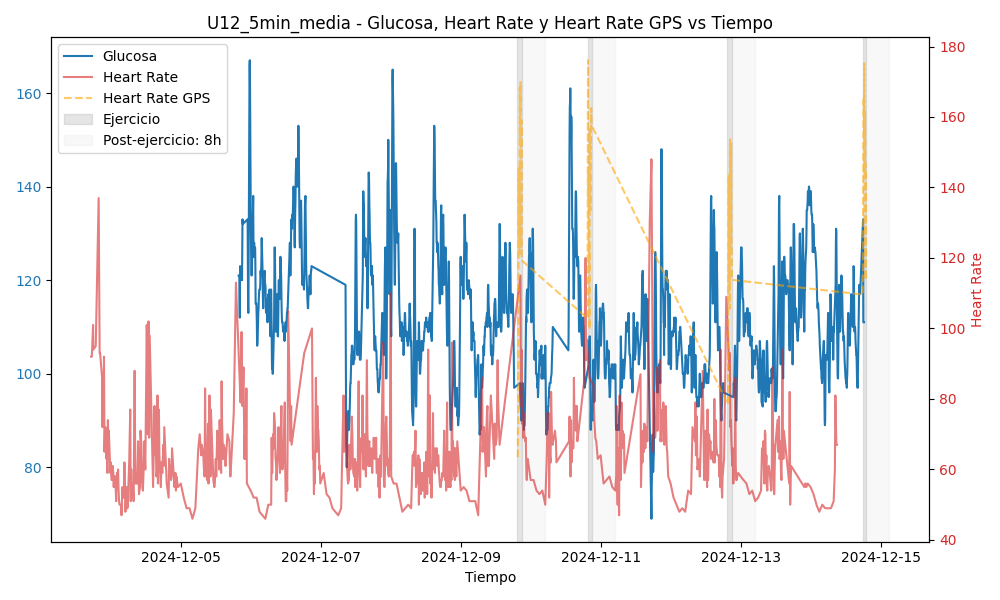

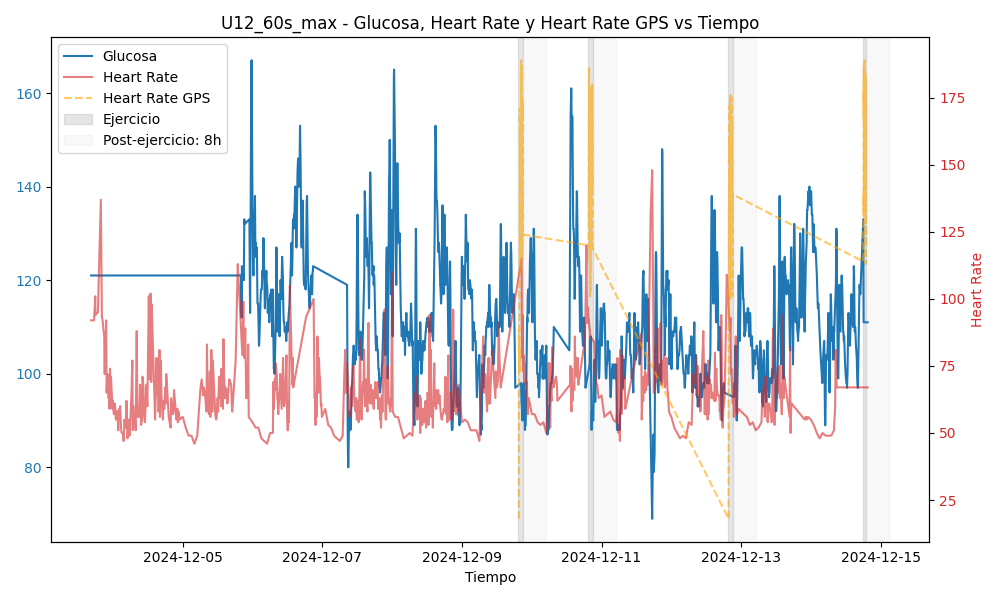

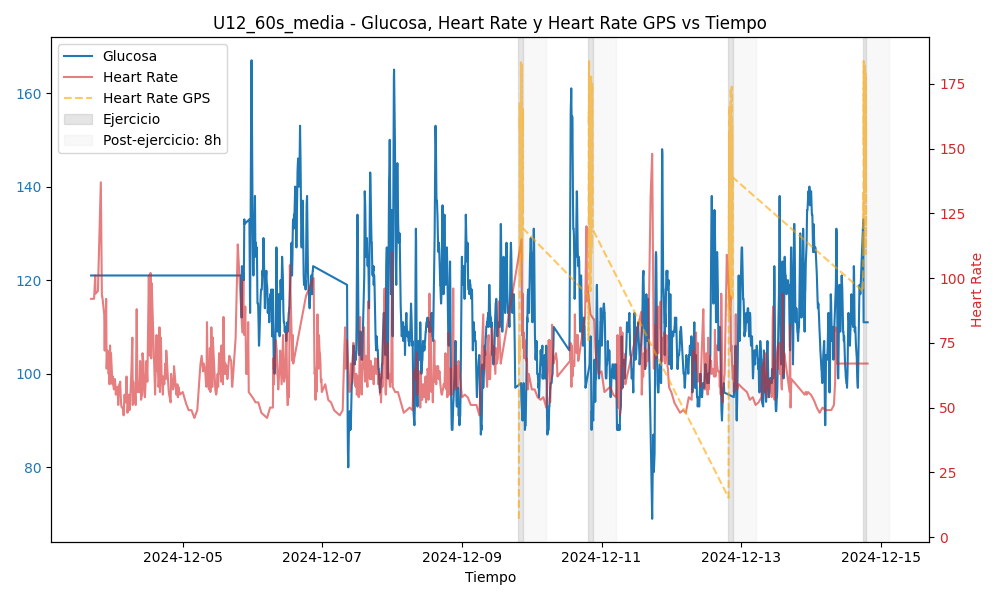

In [40]:
# GRÁFICAS DE DATOS AGRUPADOS

files = glob.glob("Data/Trusted/Agrupados/*.csv")
for archivo in files:
    graficar_glucosa_hr_trusted(archivo)

In [41]:
plt.close('all')

Aunque hemos puesto un filtro de NaNs y 0 a estas variables, aún hay datos con valor numérico miuy bajo (1.5, 1...) que pasan este filtro y por eso aún aparecen en las gráficas.